In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Información Satelelital

In [2]:
df_basic = pd.read_csv('../DataSet/DATASET_RETO_AGRO_2026/Conjunto_datos_BASICO_AgroCebada2026.csv')

print('Basic.- Info:')
df_basic.info()

Basic.- Info:
<class 'pandas.DataFrame'>
RangeIndex: 107666 entries, 0 to 107665
Data columns (total 96 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID_POLIGONO           107666 non-null  str    
 1   fecha_captura         107666 non-null  str    
 2   sensor                107666 non-null  str    
 3   ndvi_promedio         44877 non-null   float64
 4   ndvi_std              44877 non-null   float64
 5   ndvi_max              44877 non-null   float64
 6   ndvi_min              44877 non-null   float64
 7   evi_promedio          44877 non-null   float64
 8   evi_std               44877 non-null   float64
 9   evi_max               44877 non-null   float64
 10  evi_min               44877 non-null   float64
 11  crc_promedio          44877 non-null   float64
 12  crc_std               44877 non-null   float64
 13  crc_max               44877 non-null   float64
 14  crc_min               44877 non-null   float64
 1

In [10]:
df_basic.head()

,ID_POLIGONO,fecha_captura,sensor,ndvi_promedio,ndvi_std,ndvi_max,ndvi_min,evi_promedio,evi_std,evi_max,...,dswi5_min,nddi_promedio,nddi_std,nddi_max,nddi_min,enddi_promedio,enddi_std,enddi_max,enddi_min,porcentaje_nubosidad
0,AGC_011,20/04/2022,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,AGC_011,16/03/2024,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,AGC_011,15/03/2024,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,AGC_011,26/08/2025,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
4,AGC_011,10/03/2025,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [3]:
print(f'Shape csv Básico: {df_basic.shape}')


Shape csv Básico: (107666, 96)


In [4]:
print('Información por sensor: ')
print(df_basic['sensor'].value_counts())

Información por sensor: 
sensor
Sentinel-2    59040
Landsat       48626
Name: count, dtype: int64


In [5]:
df_basic[
    df_basic["sensor"] == "Landsat"
].isna().mean().sort_values(ascending=False).head(20)

ndvi_promedio     1.0
ndvi_min          1.0
ndvi_max          1.0
ndvi_std          1.0
evi_promedio      1.0
evi_min           1.0
evi_max           1.0
evi_std           1.0
crc_std           1.0
crc_max           1.0
crc_min           1.0
crc_promedio      1.0
mcrc_promedio     1.0
mcrc_min          1.0
mcrc_max          1.0
mcrc_std          1.0
srndi_std         1.0
srndi_max         1.0
srndi_min         1.0
ndsvi_promedio    1.0
dtype: float64

In [6]:
df_basic[
    df_basic["sensor"] == "Landsat"
][
    ["porcentaje_nubosidad", "ndvi_promedio", "evi_promedio"]
].describe()


,porcentaje_nubosidad,ndvi_promedio,evi_promedio
count,45570.000000,0.0,0.0
mean,36.216807,NaN,NaN
std,46.706084,NaN,NaN
min,0.000000,NaN,NaN
25%,0.000000,NaN,NaN
50%,0.000000,NaN,NaN
75%,100.000000,NaN,NaN
max,100.000000,NaN,NaN


In [7]:
df_pro = pd.read_csv('../DataSet/DATASET_RETO_AGRO_2026/Conjunto_datos_PRO_AgroCebada.csv')
print(f'Shape csv PRO: {df_pro.shape}')
df_pro.head()


Shape csv PRO: (47804, 20)


,ID_POLIGONO,fecha_captura,sensor,ndvi_promedio,ndvi_std,ndvi_max,ndvi_min,evi_promedio,evi_std,evi_max,evi_min,lai_promedio,lai_std,lai_max,lai_min,msavi_promedio,msavi_std,msavi_max,msavi_min,porcentaje_nubosidad
0,AGC_056,05/02/2025,Planet,0.300,0.042,0.553,0.175,0.138,0.022,0.251,0.068,1.049,0.182,2.144,0.586,0.135,0.022,0.244,0.066,0.0
1,AGC_056,08/02/2025,Planet,0.204,0.043,0.529,0.125,0.110,0.018,0.209,0.074,0.697,0.167,1.888,0.247,0.110,0.018,0.207,0.072,0.0
2,AGC_056,07/02/2025,Planet,0.241,0.043,0.534,0.154,0.134,0.018,0.224,0.098,0.826,0.159,1.858,0.404,0.135,0.018,0.230,0.098,0.0
3,AGC_056,09/02/2025,Planet,0.246,0.039,0.536,0.153,0.142,0.018,0.243,0.098,0.818,0.159,1.849,0.399,0.141,0.018,0.237,0.095,0.0
4,AGC_056,30/01/2025,Planet,0.211,0.046,0.533,0.113,0.110,0.020,0.229,0.069,0.724,0.187,1.955,0.277,0.111,0.021,0.230,0.067,0.0


In [8]:
print('PRO Info: ')
display(df_pro.info())

PRO Info: 
<class 'pandas.DataFrame'>
RangeIndex: 47804 entries, 0 to 47803
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID_POLIGONO           47804 non-null  str    
 1   fecha_captura         47804 non-null  str    
 2   sensor                47804 non-null  str    
 3   ndvi_promedio         35747 non-null  float64
 4   ndvi_std              35747 non-null  float64
 5   ndvi_max              35747 non-null  float64
 6   ndvi_min              35747 non-null  float64
 7   evi_promedio          35747 non-null  float64
 8   evi_std               35747 non-null  float64
 9   evi_max               35747 non-null  float64
 10  evi_min               35747 non-null  float64
 11  lai_promedio          35747 non-null  float64
 12  lai_std               35747 non-null  float64
 13  lai_max               35747 non-null  float64
 14  lai_min               35747 non-null  float64
 15  msavi_promedio     

None

In [9]:
#Información por dataframe
print(f'Elementos unicos en Basic: {df_basic["ID_POLIGONO"].nunique()}')
print(f'Elementos unicos en Pro: {df_pro["ID_POLIGONO"].nunique()}')

Elementos unicos en Basic: 197
Elementos unicos en Pro: 197


#### Análsis de frecuencia temporal

In [10]:
#Análisis fechas
df_basic['fecha_captura'] = pd.to_datetime(df_basic['fecha_captura'], dayfirst=True)
df_pro['fecha_captura'] = pd.to_datetime(df_pro['fecha_captura'], dayfirst=True)

print(f'Fecha inicio del Básico: {df_basic["fecha_captura"].min()}')
print(f'Fecha fin del Básico: {df_basic["fecha_captura"].max()}')

print(f'Fecha inicio del PRO: {df_pro["fecha_captura"].min()}')
print(f'Fecha fin del PRO: {df_pro["fecha_captura"].max()}')

Fecha inicio del Básico: 2022-01-01 00:00:00
Fecha fin del Básico: 2025-12-31 00:00:00
Fecha inicio del PRO: 2025-01-01 00:00:00
Fecha fin del PRO: 2025-12-30 00:00:00


In [11]:
#Distribución de fechas
print(f'Basic: {df_basic["fecha_captura"].dt.year.value_counts().sort_index()}\n')

print(f'PRO: {df_pro["fecha_captura"].dt.year.value_counts().sort_index()}')

Basic: fecha_captura
2022    26728
2023    27042
2024    26140
2025    27756
Name: count, dtype: int64

PRO: fecha_captura
2025    47804
Name: count, dtype: int64


In [12]:
df_pro['mes'] = df_pro['fecha_captura'].dt.month
observaciones_mes_pro = (df_pro.groupby('mes').size())

df_basic['mes'] = df_basic['fecha_captura'].dt.month
df_basic['año'] = df_basic['fecha_captura'].dt.year
observaciones_mes_basic = (df_basic.groupby(['año', 'mes', 'sensor']).size())

print(f'Observaciones al mes PRO: {observaciones_mes_pro}')
print(f'Observaciones al mes Basic: {observaciones_mes_basic}')


Observaciones al mes PRO: mes
1     4316
2     4135
3     5166
4     4760
5     4436
6     2213
7     2940
8     4381
9     3964
10    3561
11    3407
12    4525
dtype: int64
Observaciones al mes Basic: año   mes  sensor    
2022  1    Landsat        909
           Sentinel-2    1379
      2    Landsat        701
           Sentinel-2     985
      3    Landsat        736
                         ... 
2025  10   Sentinel-2    1379
      11   Landsat        971
           Sentinel-2    1515
      12   Landsat        943
           Sentinel-2    1576
Length: 96, dtype: int64


In [13]:
#Observaciones en Sentinel al mes

sentinel_mensual = (df_basic[df_basic['sensor'] == 'Sentinel-2'].groupby(['ID_POLIGONO', 'mes', 'año'])
                    .agg(observaciones=("ID_POLIGONO", "size"), ndvi_validos=("ndvi_promedio", "count")).reset_index())

print(sentinel_mensual.head(10))

  ID_POLIGONO  mes   año  observaciones  ndvi_validos
0     AGC_001    1  2022              7             5
1     AGC_001    1  2023              7             6
2     AGC_001    1  2024              7             4
3     AGC_001    1  2025              6             4
4     AGC_001    2  2022              5             5
5     AGC_001    2  2023              5             5
6     AGC_001    2  2024              5             5
7     AGC_001    2  2025              5             4
8     AGC_001    3  2022              6             5
9     AGC_001    3  2023              6             6


In [14]:
resumen_mensual = (
    sentinel_mensual
    .groupby(["año", "mes"])
    .agg(
        observaciones_promedio=("observaciones", "mean"),
        observaciones_min=("observaciones", "min"),
        observaciones_max=("observaciones", "max"),
        ndvi_validos_promedio=("ndvi_validos", "mean"),
        ndvi_validos_min=("ndvi_validos", "min"),
        ndvi_validos_max=("ndvi_validos", "max")
    )
    .reset_index()
)

print(resumen_mensual.to_string(index=False))

 año  mes  observaciones_promedio  observaciones_min  observaciones_max  ndvi_validos_promedio  ndvi_validos_min  ndvi_validos_max
2022    1                7.000000                  7                  7               5.380711                 5                 7
2022    2                5.000000                  5                  5               4.659898                 2                 5
2022    3                6.000000                  6                  6               4.923858                 4                 6
2022    4                5.670051                  5                  6               4.517766                 3                 5
2022    5                7.000000                  7                  7               5.629442                 3                 7
2022    6                6.000000                  6                  6               4.030457                 2                 6
2022    7                6.000000                  6                  6            

In [15]:
cobertura_pro = (
    df_pro
    .groupby(["mes", "ID_POLIGONO"])
    .size()
    .reset_index(name="n_observaciones")
)

print(cobertura_pro.head(20))

    mes ID_POLIGONO  n_observaciones
0     1     AGC_001               22
1     1     AGC_002               22
2     1     AGC_003               24
3     1     AGC_004               23
4     1     AGC_005               21
5     1     AGC_006               21
6     1     AGC_007               23
7     1     AGC_008               21
8     1     AGC_009               23
9     1     AGC_010               21
10    1     AGC_011               23
11    1     AGC_012               21
12    1     AGC_013               21
13    1     AGC_014               21
14    1     AGC_015               21
15    1     AGC_016               22
16    1     AGC_017               21
17    1     AGC_018               23
18    1     AGC_019               22
19    1     AGC_020               21


In [16]:
cobertura_pro.groupby("mes")["n_observaciones"].describe()

,count,mean,std,min,25%,50%,75%,max
mes,,,,,,,,
1,197.0,21.908629,0.980304,20.0,21.0,22.0,23.0,24.0
2,197.0,20.989848,2.511179,16.0,18.0,23.0,23.0,24.0
3,197.0,26.223350,1.505386,23.0,25.0,27.0,27.0,30.0
4,197.0,24.162437,2.328617,19.0,22.0,26.0,26.0,26.0
5,197.0,22.517766,1.047806,20.0,22.0,23.0,23.0,24.0
6,197.0,11.233503,1.777494,8.0,10.0,11.0,13.0,16.0
7,197.0,14.923858,1.087634,13.0,14.0,15.0,16.0,17.0
8,197.0,22.238579,1.840290,18.0,21.0,23.0,24.0,24.0
9,197.0,20.121827,1.724784,18.0,19.0,19.0,21.0,24.0


### Datos rendimientos

In [17]:
df_rend = pd.read_csv('../DataSet/DATASET_RETO_AGRO_2026/ID_area_rendimiento_70_30_Reto_AgroCebada.csv')
df_rend.head()

,ID_POLIGONO,AREA_HA,RENDIMIENTO_T_HA,CONJUNTO,Unnamed: 4
0,AGC_001,7.61,3.50,ENTRENAMIENTO,NaN
1,AGC_002,2.31,4.63,ENTRENAMIENTO,NaN
2,AGC_003,18.68,NaN,PREDICCION,NaN
3,AGC_004,8.00,3.00,ENTRENAMIENTO,NaN
4,AGC_005,2.27,5.16,ENTRENAMIENTO,NaN


In [18]:
print(f'shape csv Rendimiento: {df_rend.shape}')

shape csv Rendimiento: (197, 5)


In [19]:
print('Rendimiento Info: ')
display(df_rend.info())

Rendimiento Info: 
<class 'pandas.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_POLIGONO       197 non-null    str    
 1   AREA_HA           197 non-null    float64
 2   RENDIMIENTO_T_HA  138 non-null    float64
 3   CONJUNTO          197 non-null    str    
 4   Unnamed: 4        0 non-null      float64
dtypes: float64(3), str(2)
memory usage: 7.8 KB


None

In [20]:
df_rend['CONJUNTO'].value_counts()

CONJUNTO
ENTRENAMIENTO    138
PREDICCION        59
Name: count, dtype: int64

In [21]:
print(
    pd.crosstab(
        df_rend["CONJUNTO"],
        df_rend["RENDIMIENTO_T_HA"].isna()
    )
)


RENDIMIENTO_T_HA  False  True 
CONJUNTO                      
ENTRENAMIENTO       138      0
PREDICCION            0     59


In [22]:
#Comprobación de tamaño de parcelas
ids_basic = set(df_basic['ID_POLIGONO'])
ids_pro = set(df_pro['ID_POLIGONO'])
ids_rend = set(df_rend["ID_POLIGONO"])

print(f'Basic: {len(ids_basic)}')
print(f'Pro: {len(ids_pro)}')
print(f'Rendimiento: {len(ids_rend)}')

Basic: 197
Pro: 197
Rendimiento: 197


### Análisis de NDVI

In [23]:
df_pro['ndvi_valido'] = df_pro['ndvi_promedio'].notna()
validos_pro = df_pro.groupby('mes')['ndvi_valido'].agg(observaciones='count', validas='sum')
validos_pro['porcentaje_validas'] = (validos_pro['validas'] / validos_pro['observaciones']) * 100

print('Validos pro')
print(validos_pro)

Validos pro
     observaciones  validas  porcentaje_validas
mes                                            
1             4316     3057           70.829472
2             4135     3401           82.249093
3             5166     4939           95.605885
4             4760     4476           94.033613
5             4436     3118           70.288548
6             2213     1222           55.219160
7             2940     1796           61.088435
8             4381     3215           73.385072
9             3964     2142           54.036327
10            3561     2279           63.998877
11            3407     2951           86.615791
12            4525     3151           69.635359


In [24]:
df_basic['ndvi_valido'] = df_basic['ndvi_promedio'].notna()

validos_basic = df_basic.groupby(['año', 'mes', 'sensor'])['ndvi_valido'].agg(observaciones='count', validas='sum')
validos_basic['porcentaje_validas'] = (validos_basic['validas'] / validos_basic['observaciones']) * 100

print('Validos Basic')
print(validos_basic)

Validos Basic
                     observaciones  validas  porcentaje_validas
año  mes sensor                                                
2022 1   Landsat               909        0            0.000000
         Sentinel-2           1379     1060           76.867295
     2   Landsat               701        0            0.000000
         Sentinel-2            985      918           93.197970
     3   Landsat               736        0            0.000000
...                            ...      ...                 ...
2025 10  Sentinel-2           1379     1029           74.619289
     11  Landsat               971        0            0.000000
         Sentinel-2           1515     1498           98.877888
     12  Landsat               943        0            0.000000
         Sentinel-2           1576     1138           72.208122

[96 rows x 3 columns]


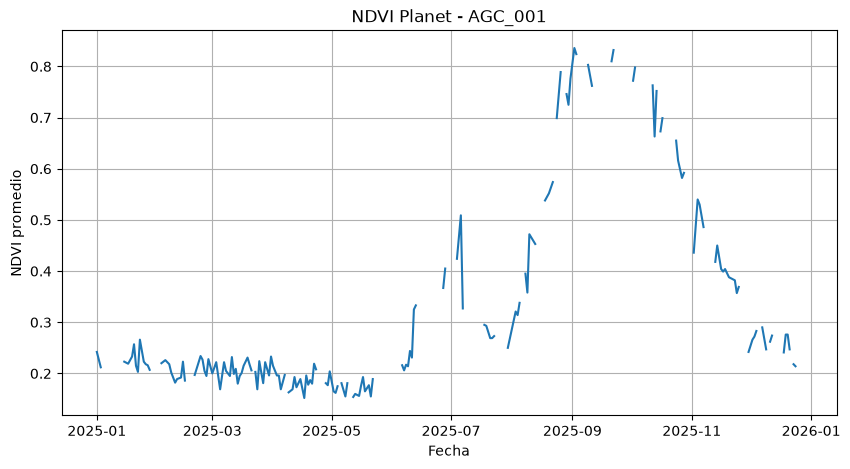

In [25]:
parcela = 'AGC_001'

serie = df_pro[df_pro['ID_POLIGONO'] == parcela].sort_values('fecha_captura')

plt.figure(figsize=(10, 5))

plt.plot(serie['fecha_captura'], serie['ndvi_promedio'])
plt.xlabel("Fecha")
plt.ylabel("NDVI promedio")
plt.title(f"NDVI Planet - {parcela}")
plt.grid(True)
plt.show()

#### Análisis de datos faltantes

In [26]:
resumen_basico = pd.DataFrame({
    "tipo": df_basic.dtypes,
    "no_nulos": df_basic.notna().sum(),
    "nulos": df_basic.isna().sum(),
    "porcentaje_validos": df_basic.notna().mean() * 100,
    "unicos": df_basic.nunique()
})

resumen_basico = resumen_basico.sort_values("porcentaje_validos")
print(resumen_basico)

                  tipo  no_nulos  nulos  porcentaje_validos  unicos
vi6t_promedio  float64     31048  76618           28.837330     229
vi6t_min       float64     31048  76618           28.837330     237
vi6t_max       float64     31048  76618           28.837330     301
vi6t_std       float64     31048  76618           28.837330      65
fapar_std      float64     44873  62793           41.677967     223
...                ...       ...    ...                 ...     ...
sensor             str    107666      0          100.000000       2
ID_POLIGONO        str    107666      0          100.000000     197
mes              int32    107666      0          100.000000      12
año              int32    107666      0          100.000000       4
ndvi_valido       bool    107666      0          100.000000       2

[99 rows x 5 columns]


In [27]:
#Features of the basic csv

print(df_basic.columns.tolist())

['ID_POLIGONO', 'fecha_captura', 'sensor', 'ndvi_promedio', 'ndvi_std', 'ndvi_max', 'ndvi_min', 'evi_promedio', 'evi_std', 'evi_max', 'evi_min', 'crc_promedio', 'crc_std', 'crc_max', 'crc_min', 'mcrc_promedio', 'mcrc_std', 'mcrc_max', 'mcrc_min', 'ndsvi_promedio', 'ndsvi_std', 'ndsvi_max', 'ndsvi_min', 'srndi_promedio', 'srndi_std', 'srndi_max', 'srndi_min', 'mra_promedio', 'mra_std', 'mra_max', 'mra_min', 'lai_promedio', 'lai_std', 'lai_max', 'lai_min', 'fapar_promedio', 'fapar_std', 'fapar_max', 'fapar_min', 'savi_promedio', 'savi_std', 'savi_max', 'savi_min', 'vi6t_promedio', 'vi6t_std', 'vi6t_max', 'vi6t_min', 'ndti_promedio', 'ndti_std', 'ndti_max', 'ndti_min', 'sti_promedio', 'sti_std', 'sti_max', 'sti_min', 'ndwi_promedio', 'ndwi_std', 'ndwi_max', 'ndwi_min', 'endwi_promedio', 'endwi_std', 'endwi_max', 'endwi_min', 'msi_promedio', 'msi_std', 'msi_max', 'msi_min', 'emsi_promedio', 'emsi_std', 'emsi_max', 'emsi_min', 'dswi2_promedio', 'dswi2_std', 'dswi2_max', 'dswi2_min', 'dswi3_

In [28]:
columns_no_num = df_basic.select_dtypes(exclude="number").columns.tolist()
columns_num = df_basic.select_dtypes(include="number").columns.tolist()

print('Features de tupo num: ')
print(columns_num, '\n ')

print('Features de tipo no numéricas: ')
print(columns_no_num, '\n ')

Features de tupo num: 
['ndvi_promedio', 'ndvi_std', 'ndvi_max', 'ndvi_min', 'evi_promedio', 'evi_std', 'evi_max', 'evi_min', 'crc_promedio', 'crc_std', 'crc_max', 'crc_min', 'mcrc_promedio', 'mcrc_std', 'mcrc_max', 'mcrc_min', 'ndsvi_promedio', 'ndsvi_std', 'ndsvi_max', 'ndsvi_min', 'srndi_promedio', 'srndi_std', 'srndi_max', 'srndi_min', 'mra_promedio', 'mra_std', 'mra_max', 'mra_min', 'lai_promedio', 'lai_std', 'lai_max', 'lai_min', 'fapar_promedio', 'fapar_std', 'fapar_max', 'fapar_min', 'savi_promedio', 'savi_std', 'savi_max', 'savi_min', 'vi6t_promedio', 'vi6t_std', 'vi6t_max', 'vi6t_min', 'ndti_promedio', 'ndti_std', 'ndti_max', 'ndti_min', 'sti_promedio', 'sti_std', 'sti_max', 'sti_min', 'ndwi_promedio', 'ndwi_std', 'ndwi_max', 'ndwi_min', 'endwi_promedio', 'endwi_std', 'endwi_max', 'endwi_min', 'msi_promedio', 'msi_std', 'msi_max', 'msi_min', 'emsi_promedio', 'emsi_std', 'emsi_max', 'emsi_min', 'dswi2_promedio', 'dswi2_std', 'dswi2_max', 'dswi2_min', 'dswi3_promedio', 'dswi3_s

In [29]:
index_name = set()
words_to_delete =  ["min", "max", "promedio", "std"]

for col in columns_num:
    split_col = col.split('_')
    if len(split_col) > 1:
        if split_col[0] in col and split_col[1] in words_to_delete:
            index_name.add(split_col[0])
        else: 
            continue
    else:
        continue
    
print(index_name)
print(len(index_name))

{'ndwi', 'dswi2', 'endwi', 'fapar', 'dswi3', 'savi', 'dswi5', 'mra', 'ndti', 'dswi4', 'evi', 'srndi', 'vi6t', 'msi', 'mcrc', 'emsi', 'lai', 'sti', 'enddi', 'ndsvi', 'nddi', 'crc', 'ndvi'}
23


Tenemos 23 variables que se miden del satélite, para cada variable se obtiene su valor mínimo, máximo, promedio y desviación estándar.

In [30]:
#Checamos los datos faltante para ca variable, para ver la calidad de datos.

resumen_indices = []

for indice in index_name:
    columnas = [
        f"{indice}_promedio",
        f"{indice}_std",
        f"{indice}_max",
        f"{indice}_min"
    ]
    
    porcentaje_valido = df_basic[columnas].notna().mean().mean() * 100
    
    resumen_indices.append({
        "indice": indice,
        "porcentaje_valido": porcentaje_valido
    })

resumen_indices = pd.DataFrame(resumen_indices)

resumen_indices = resumen_indices.sort_values(
    "porcentaje_valido",
    ascending=False
)

print(resumen_indices.to_string(index=False))

indice  porcentaje_valido
  ndwi          41.681682
 dswi2          41.681682
 endwi          41.681682
 dswi3          41.681682
  savi          41.681682
 dswi5          41.681682
   mra          41.681682
 ndsvi          41.681682
  ndti          41.681682
 dswi4          41.681682
   evi          41.681682
 srndi          41.681682
   msi          41.681682
  mcrc          41.681682
  emsi          41.681682
   crc          41.681682
   lai          41.681682
   sti          41.681682
 enddi          41.681682
  ndvi          41.681682
  nddi          41.681682
 fapar          41.677967
  vi6t          28.837330


De los 23 índices en promedio del 41% de sus datos son validos.

In [31]:
comparacion_sensor = (
    df_basic
    .groupby("sensor")
    .agg(
        registros=("ID_POLIGONO", "size"),
        ndvi_validos=("ndvi_promedio", "count"),
        evi_validos=("evi_promedio", "count"),
        lai_validos=("lai_promedio", "count"),
        vi6t_validos=("vi6t_promedio", "count"),
        fapar_validos=("fapar_promedio", "count"),
        nubosidad_media=("porcentaje_nubosidad", "mean")
    )
)

print(comparacion_sensor)

            registros  ndvi_validos  evi_validos  lai_validos  vi6t_validos  \
sensor                                                                        
Landsat         48626             0            0            0         31048   
Sentinel-2      59040         44877        44877        44877             0   

            fapar_validos  nubosidad_media  
sensor                                      
Landsat                 0        36.216807  
Sentinel-2          44873        29.192712  


Podemos decir que cada satélite da información diferente, por eso Landsat no tiene cierta información pero si Sentinel, Landasat si tiene info acerca de VI6T.

In [32]:
#Revisamos a que índice pertence cada sensor

for sensor in df_basic['sensor'].unique():
    print(f'Sensor {sensor}')
    
    columnas_validas = []
    
    for indice in index_name:
        column = f'{indice}_promedio'
        
        if df_basic.loc[df_basic['sensor'] == sensor, column].notna().any():
            columnas_validas.append(indice)
        
    print('Indices:')
    print(columnas_validas, '\n')
    print(f'Cantidad de índices {len(columnas_validas)}')

Sensor Landsat
Indices:
['vi6t'] 

Cantidad de índices 1
Sensor Sentinel-2
Indices:
['ndwi', 'dswi2', 'endwi', 'fapar', 'dswi3', 'savi', 'dswi5', 'mra', 'ndti', 'dswi4', 'evi', 'srndi', 'msi', 'mcrc', 'emsi', 'lai', 'sti', 'enddi', 'ndsvi', 'nddi', 'crc', 'ndvi'] 

Cantidad de índices 22


In [33]:
observaciones_sensor_anio = (
    df_basic
    .groupby(["sensor", "año"])
    .size()
    .unstack(fill_value=0)
)

print(observaciones_sensor_anio)

año          2022   2023   2024   2025
sensor                                
Landsat     12806  13125  11759  10936
Sentinel-2  13922  13917  14381  16820


In [34]:
validos_sensor_anio = (
    df_basic
    .groupby(["sensor", "año"])["ndvi_promedio"]
    .count()
    .unstack(fill_value=0)
)

print(validos_sensor_anio)


año          2022   2023   2024   2025
sensor                                
Landsat         0      0      0      0
Sentinel-2  10045  10301  11440  13091


In [35]:
observaciones_por_parcela_sentinel = (df_basic[df_basic['sensor'] == 'Sentinel-2'].groupby('ID_POLIGONO')
                                      .agg(observaciones=('ID_POLIGONO', 'size'), ndvi_validos=('ndvi_promedio', 'count')))

print(observaciones_por_parcela_sentinel.describe())
display(observaciones_por_parcela_sentinel.head(5))

       observaciones  ndvi_validos
count     197.000000    197.000000
mean      299.695431    227.802030
std         1.350974      8.764283
min       298.000000    210.000000
25%       298.000000    222.000000
50%       300.000000    227.000000
75%       301.000000    235.000000
max       301.000000    247.000000


,observaciones,ndvi_validos
ID_POLIGONO,,
AGC_001,298,235
AGC_002,301,225
AGC_003,299,222
AGC_004,298,237
AGC_005,301,215


Observaciones por parcel con Senrtinel son de 299

In [36]:
print(f'Serie: {serie}')

Serie:       ID_POLIGONO fecha_captura  sensor  ndvi_promedio  ndvi_std  ndvi_max  \
43071     AGC_001    2025-01-01  Planet          0.242     0.024     0.382   
43072     AGC_001    2025-01-03  Planet          0.212     0.022     0.322   
43229     AGC_001    2025-01-05  Planet            NaN       NaN       NaN   
43231     AGC_001    2025-01-06  Planet            NaN       NaN       NaN   
43230     AGC_001    2025-01-07  Planet            NaN       NaN       NaN   
...           ...           ...     ...            ...       ...       ...   
42997     AGC_001    2025-12-24  Planet          0.214     0.044     0.523   
43191     AGC_001    2025-12-25  Planet            NaN       NaN       NaN   
43001     AGC_001    2025-12-27  Planet          0.239     0.040     0.479   
43196     AGC_001    2025-12-28  Planet            NaN       NaN       NaN   
43180     AGC_001    2025-12-30  Planet            NaN       NaN       NaN   

       ndvi_min  evi_promedio  evi_std  evi_max  ...  la

## Shape files .- Parcelas del cultivo

In [37]:
import geopandas as gpd
import matplotlib.pyplot as plt

In [80]:
parcelas_gdf = gpd.read_file('../DataSet/DATASET_RETO_AGRO_2026/Parcelas_Reto_AGC_CONJUNTO_70_30/Parcelas_Reto_AGC_CONJUNTO.shp')

parcela_gdf.head()

,Cultivo,ID_POLIGON,área_ha,Municipio,Estado,CONJUNTO,geometry
0,Cebada,AGC_196,8.57,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.57739 19.65802 0, -98.57751 19..."
1,Cebada,AGC_044,0.68,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58655 19.62943 0, -98.5862 19...."
2,Cebada,AGC_020,8.34,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58494 19.6278 0, -98.58656 19...."
3,CEBADA,AGC_174,6.89,Cuautepec de Hinojosa,Hidalgo,PREDICCION,"POLYGON Z ((-98.30604 19.9 0, -98.30486 19.899..."
4,CEBADA,AGC_083,2.87,Cuautepec de Hinojosa,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.29383 19.8882 0, -98.29378 19...."


In [83]:
print(f'Shape: {parcelas_gdf.shape}')
print(f'CRS: {parcelas_gdf.crs}')
print(f'Columns: {parcelas_gdf.columns}')

Shape: (197, 7)
CRS: EPSG:4326
Columns: Index(['Cultivo', 'ID_POLIGON', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO',
       'geometry'],
      dtype='str')


4326 significa que la geometría esta expresado en latitud y longitud.

In [84]:
#Tipo de geometría
print(f'Tipo geometría: {parcelas_gdf.geometry.geom_type.value_counts()}')
print(f'Info: {parcelas_gdf.info()}')

Tipo geometría: Polygon    197
Name: count, dtype: int64
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Cultivo     197 non-null    str     
 1   ID_POLIGON  197 non-null    str     
 2   área_ha     197 non-null    float64 
 3   Municipio   197 non-null    str     
 4   Estado      197 non-null    str     
 5   CONJUNTO    197 non-null    str     
 6   geometry    197 non-null    geometry
dtypes: float64(1), geometry(1), str(5)
memory usage: 10.9 KB
Info: None


## Raster Precipitación

In [42]:
import rasterio 

precipitation_path = '../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Precipitacion_mensual/2025/PREC_2025_01.tif'

with rasterio.open(precipitation_path) as src:
    print('CRS: ', src.crs)
    print('Dimensiones: ', src.width, src.height)
    print('Número de bandas: ', src.count)
    print('Resolución: ', src.res)
    print('Bounds: ', src.bounds)
    print('No Data: ', src.nodata)
    print('tipo de dato: ', src.dtypes)

CRS:  EPSG:4326
Dimensiones:  65 72
Número de bandas:  1
Resolución:  (0.05000000074505806, 0.05000000074505806)
Bounds:  BoundingBox(left=-99.94999880716205, bottom=17.79999952018261, right=-96.69999875873327, top=21.39999957382679)
No Data:  -9999.0
tipo de dato:  ('float32',)


CRS: EPSG:4326
Resolución: (0.05000000074505806, 0.05000000074505806)
Shape: 72 65
NoData: -9999.0
Bounds: BoundingBox(left=-99.94999880716205, bottom=17.79999952018261, right=-96.69999875873327, top=21.39999957382679)
Valor mínimo:  1.4133751
Valor máximo:  93.62358
Promedio:  21.839315


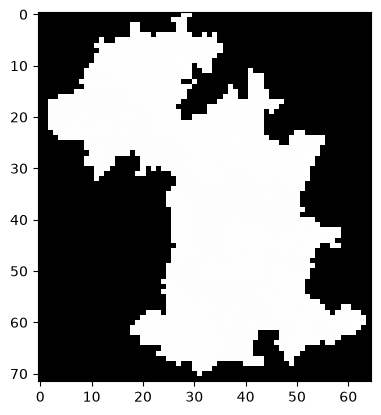

In [145]:
with rasterio.open(precipitation_path) as src:
    precipitation = src.read(1)


print("CRS:", src.crs)
print("Resolución:", src.res)
print("Shape:", src.height, src.width)
print("NoData:", src.nodata)
print("Bounds:", src.bounds)
print('Valor mínimo: ', np.nanmin(np.where(precipitation == -9999, np.nan, precipitation)))
print('Valor máximo: ', np.nanmax(np.where(precipitation == -9999, np.nan, precipitation)))
print('Promedio: ', np.nanmean(np.where(precipitation == -9999, np.nan, precipitation))) 

    
plt.imshow(precipitation, cmap='gray')

### Precipitación + Parcel

In [147]:
#Hacemos la parcela y raster estén el mismo formato.

with rasterio.open(precipitation_path) as src:
    parcela_01 = parcela_repro.to_crs(src.crs)
    
    

In [1]:
with rasterio.open(precipitation_path) as src:
    src.read(1)
    extent = [src.bounds.left, src.bounds.right, src.bounds.top, src.bounds.bottom]
    
fig, ax = plt.subplots(figsize=(8, 6))

precipitation_map = precipitation.astype(float)
precipitation_map[precipitation_map == -9999] = np.nan

ax.imshow(precipitation_map, extent=extent, origin='upper')
parcelas_gdf.boundary.plot(ax=ax, linewidth =0.5)

ax.set_title("Precipitación abril 2025 + parcelas")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

plt.show()

NameError: name 'rasterio' is not defined

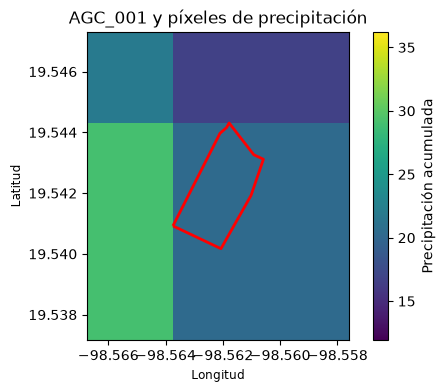

In [152]:
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent
from rasterio.windows import from_bounds

parcela_001 = parcelas_gdf[
    parcelas_gdf["ID_POLIGON"] == "AGC_001"
].copy()

with rasterio.open(precipitation_path) as src:

    # Parcela en CRS del raster
    parcela_001_4326 = parcela_001.to_crs(src.crs)

    xmin, ymin, xmax, ymax = parcela_001_4326.total_bounds

    # Margen de 0.1 grados
    margen = 0.1

    window = from_bounds(
        xmin - margen,
        ymin - margen,
        xmax + margen,
        ymax + margen,
        src.transform
    )

    precipitacion = src.read(
        1,
        window=window
    )

    transform_window = src.window_transform(window)

    precipitacion = precipitacion.astype(float)
    precipitacion[
        precipitacion == src.nodata
    ] = np.nan

    extent = plotting_extent(
        precipitacion,
        transform_window
    )

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(
    precipitacion,
    extent=extent,
    origin="upper"
)

parcela_001_4326.boundary.plot(
    ax=ax,
    linewidth=2,
    color="red"
)

ax.set_title(
    "AGC_001 y píxeles de precipitación"
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

plt.colorbar(
    im,
    ax=ax,
    label="Precipitación acumulada"
)

# Límites de la parcela
xmin, ymin, xmax, ymax = parcela_001_4326.total_bounds

# Ampliar la visualización alrededor de la parcela
margen = 0.003

ax.set_xlim(xmin - margen, xmax + margen)
ax.set_ylim(ymin - margen, ymax + margen)

plt.show()

Extraemos los datos sobre precipitación.

In [154]:
from pyproj import Transformer
import shapely

In [178]:
def get_precipitation(raster_path, parcela):
    with rasterio.open(raster_path) as src:
        parcela_geom = parcela.to_crs(src.crs)
        parcela_geom = parcela_geom.geometry.iloc[0]
        
        #Recortamos los pixeles del raster que intersacatn con la parcela
        values, transform = mask(src, [mapping(parcela_geom)], crop=True, filled=False, all_touched=True)
        
        #Objeto para transformar de coordendas a metros
        transfomer = Transformer.from_crs(src.crs, 'EPSG:6372', always_xy=True)
        
        #Parcela en metros
        parcela_m = parcela.to_crs('EPSG:6372')
        geometry_m = parcela_m.geometry.iloc[0]
        
        area_total = geometry_m.area
        area_valida = 0
        suma_ponderada = 0
        pixeles_validos = 0
        
        for i in range(values.shape[1]):
            for j in range(values.shape[2]):
                
                #Ignoramos los pixeles que no tienen datos
                if  np.ma.getmaskarray(values)[0, i, j]:
                    continue
                
                valor = float(values[0, i, j])

                if not np.isfinite(valor):
                    continue

                # Límites del píxel en el CRS del raster
                x1, y1 = xy(transform, i, j, offset="ul")

                x2, y2 = xy(transform, i, j, offset="lr")

                pixel_geo = box(x1, y2, x2, y1)

                # Transformar el píxel a coordenadas métricas
                pixel_m = shapely.ops.transform(transfomer.transform,pixel_geo)

                # Intersección real con la parcela
                interseccion = pixel_m.intersection(geometry_m)
                area_interseccion = interseccion.area

                if area_interseccion <= 0:
                    continue

                area_valida += area_interseccion
                suma_ponderada += valor * area_interseccion
                pixeles_validos += 1

        media_ponderada = (
            suma_ponderada / area_valida
            if area_valida > 0
            else np.nan
        )

        return {
            "area_total_m2": area_total,
            "area_valida_m2": area_valida,
            "cobertura_pct": 100 * area_valida / area_total,
            "precipitacion_media": media_ponderada,
            "pixeles_validos": pixeles_validos
        }

In [179]:
precipitation_results = []

for _, parcela in parcelas_gdf.iterrows():
    parcela_gdf = gpd.GeoDataFrame([parcela], geometry="geometry",crs=parcelas_gdf.crs)
    
    result = get_precipitation(precipitation_path, parcela_gdf)
    result["ID_POLIGON"] = parcela["ID_POLIGON"]

    precipitation_results.append(result)
    

In [180]:
precipitation_df = pd.DataFrame(precipitation_results)

precipitation_df = precipitation_df[
    [
        "ID_POLIGON",
        "precipitacion_media",
        "cobertura_pct",
        "pixeles_validos",
        "area_total_m2",
        "area_valida_m2"
    ]
]

display(precipitation_df.head())

,ID_POLIGON,precipitacion_media,cobertura_pct,pixeles_validos,area_total_m2,area_valida_m2
0,AGC_196,11.715059,100.0,1,85130.668788,85130.668788
1,AGC_044,14.340641,100.0,1,6760.402971,6760.402971
2,AGC_020,14.340641,100.0,1,82856.226598,82856.226598
3,AGC_174,18.443747,100.0,1,68423.862739,68423.862739
4,AGC_083,17.910559,100.0,1,28466.739798,28466.739798


In [181]:
print("Dimensiones:", precipitation_df.shape)
print("IDs únicos:", precipitation_df["ID_POLIGON"].nunique())
print("IDs duplicados:", precipitation_df["ID_POLIGON"].duplicated().sum())


Dimensiones: (197, 6)
IDs únicos: 197
IDs duplicados: 0


In [183]:
print(precipitation_df["precipitacion_media"].describe())

count    197.000000
mean      17.396512
std        3.672336
min       11.715059
25%       14.107316
50%       17.910559
75%       18.093159
max       32.748020
Name: precipitacion_media, dtype: float64


la media es de 17.40 mm, pero el máximo alcanza 32.75 mm. Esto indica variación espacial entre las parcelas

In [185]:
print(precipitation_df["cobertura_pct"].describe())

print(
    precipitation_df[precipitation_df["cobertura_pct"] < 99.999][["ID_POLIGON", "cobertura_pct", "precipitacion_media"]])

print(
    "Parcelas sin precipitación:",precipitation_df["precipitacion_media"].isna().sum())

count    1.970000e+02
mean     1.000000e+02
std      8.816397e-12
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
Name: cobertura_pct, dtype: float64
Empty DataFrame
Columns: [ID_POLIGON, cobertura_pct, precipitacion_media]
Index: []
Parcelas sin precipitación: 0


Ahora lo aplicamos para todos los archivos que hay en la carpeta de precipitación.

In [186]:
from pathlib import Path

In [193]:
precipitaion_dir = Path('../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Precipitacion_mensual/')
precipitation_files = sorted(precipitaion_dir.glob("*/*.tif"))

print(f'Número total de archivos: {len(precipitation_files)}')

for archivo in precipitation_files[:5]:
    print(archivo.name)


Número total de archivos: 48
PREC_2022_01.tif
PREC_2022_02.tif
PREC_2022_03.tif
PREC_2022_04.tif
PREC_2022_05.tif


In [231]:
def get_file_date(root):
    file_no_extension = root.with_suffix('') #To delete extendion .tif
    file_name = file_no_extension.name
    file_name_elements = file_name.split('_')
    variable_name = file_name_elements[0]
    year = int(file_name_elements[1])
    month = int(file_name_elements[2])
        
    return variable_name, year, month

In [232]:
for file in precipitation_files[:5]:
    variable, year, month = get_file_date(file)
    print(f'{file.name} ---> year: {year}, month: {month}')

PREC_2022_01.tif ---> year: 2022, month: 1
PREC_2022_02.tif ---> year: 2022, month: 2
PREC_2022_03.tif ---> year: 2022, month: 3
PREC_2022_04.tif ---> year: 2022, month: 4
PREC_2022_05.tif ---> year: 2022, month: 5


In [233]:
def process_monthly_precipitation(root, parcelas_gdf):
    
    variable_name, year, month = get_file_date(root)
    results = []

    for _, parcela in parcelas_gdf.iterrows():

        parcela_gdf = gpd.GeoDataFrame(
            [parcela],
            geometry="geometry",
            crs=parcelas_gdf.crs
        )

        result = get_precipitation(
            str(root),
            parcela_gdf
        )

        results.append({
            "ID_POLIGON": parcela["ID_POLIGON"],
            "año": year,
            "mes": month,
            "precipitacion_mm": result["precipitacion_media"],
            "cobertura_pct": result["cobertura_pct"],
            "pixeles_validos": result["pixeles_validos"]
        })

    return pd.DataFrame(results)

In [235]:
archivos_prueba = [
    ruta for ruta in precipitation_files
    if get_file_date(ruta)[1] == 2025
    and get_file_date(ruta)[2] in [1, 2, 3]
]

resultados_prueba = []

for ruta in archivos_prueba:
    df_mes = process_monthly_precipitation(
        ruta,
        parcelas_gdf
    )

    resultados_prueba.append(df_mes)

df_precipitacion_prueba = pd.concat(
    resultados_prueba,
    ignore_index=True
)

print("Dimensiones:", df_precipitacion_prueba.shape)
print(
    "Parcelas únicas:",
    df_precipitacion_prueba["ID_POLIGON"].nunique()
)
print(
    "Meses procesados:",
    sorted(df_precipitacion_prueba["mes"].unique())
)

Dimensiones: (591, 6)
Parcelas únicas: 197
Meses procesados: [np.int64(1), np.int64(2), np.int64(3)]


In [207]:
print(
    df_precipitacion_prueba.groupby(
        ["año", "mes"]
    )["precipitacion_mm"].agg(
        ["count", "mean", "min", "max"]
    )
)

print(
    "Valores faltantes:",
    df_precipitacion_prueba["precipitacion_mm"].isna().sum()
)

          count       mean        min        max
año  mes                                        
2025 1      197  17.396512  11.715059  32.748020
     2      197  35.989621  21.757489  61.019646
     3      197   8.726093   4.984048  12.611456
Valores faltantes: 0


Ahora si procesamos los 48 archivos que tenemos de precipitación de 2022 a 2025.

In [211]:
results_precipitation_all = []

for i, root in enumerate(precipitation_files, start=1):
    df_mes = process_monthly_precipitation(root, parcelas_gdf)
    results_precipitation_all.append(df_mes)
    
    print(f'{i}/{len(precipitation_files)}: {root.name}')

#unimos todos los meses
df_precipitation = pd.concat(results_precipitation_all, ignore_index=True)

print("\nDimensiones:", df_precipitation.shape)
print("Parcelas únicas:", df_precipitation["ID_POLIGON"].nunique())
print("Años:", sorted(df_precipitation["año"].unique()))
print("Meses:", sorted(df_precipitation["mes"].unique()))

1/48: PREC_2022_01.tif
2/48: PREC_2022_02.tif
3/48: PREC_2022_03.tif
4/48: PREC_2022_04.tif
5/48: PREC_2022_05.tif
6/48: PREC_2022_06.tif
7/48: PREC_2022_07.tif
8/48: PREC_2022_08.tif
9/48: PREC_2022_09.tif
10/48: PREC_2022_10.tif
11/48: PREC_2022_11.tif
12/48: PREC_2022_12.tif
13/48: PREC_2023_01.tif
14/48: PREC_2023_02.tif
15/48: PREC_2023_03.tif
16/48: PREC_2023_04.tif
17/48: PREC_2023_05.tif
18/48: PREC_2023_06.tif
19/48: PREC_2023_07.tif
20/48: PREC_2023_08.tif
21/48: PREC_2023_09.tif
22/48: PREC_2023_10.tif
23/48: PREC_2023_11.tif
24/48: PREC_2023_12.tif
25/48: PREC_2024_01.tif
26/48: PREC_2024_02.tif
27/48: PREC_2024_03.tif
28/48: PREC_2024_04.tif
29/48: PREC_2024_05.tif
30/48: PREC_2024_06.tif
31/48: PREC_2024_07.tif
32/48: PREC_2024_08.tif
33/48: PREC_2024_09.tif
34/48: PREC_2024_10.tif
35/48: PREC_2024_11.tif
36/48: PREC_2024_12.tif
37/48: PREC_2025_01.tif
38/48: PREC_2025_02.tif
39/48: PREC_2025_03.tif
40/48: PREC_2025_04.tif
41/48: PREC_2025_05.tif
42/48: PREC_2025_06.tif
4

In [213]:

print(
    "Duplicados:",
    df_precipitation.duplicated(
        subset=["ID_POLIGON", "año", "mes"]
    ).sum()
)

print(
    "\nFilas por año:",
    df_precipitation.groupby("año").size().to_dict()
)

print(
    "\nParcelas por mes:",
    df_precipitation.groupby(["año", "mes"])
    ["ID_POLIGON"].nunique().value_counts().to_dict()
)

print(
    "\nValores faltantes:\n",
    df_precipitation[
        ["precipitacion_mm", "cobertura_pct"]
    ].isna().sum()
)

print(
    "\nCobertura mínima por mes:\n",
    df_precipitation.groupby(["año", "mes"])
    ["cobertura_pct"].min()
)


Duplicados: 0

Filas por año: {2022: 2364, 2023: 2364, 2024: 2364, 2025: 2364}

Parcelas por mes: {197: 48}

Valores faltantes:
 precipitacion_mm    0
cobertura_pct       0
dtype: int64

Cobertura mínima por mes:
 año   mes
2022  1      100.0
      2      100.0
      3      100.0
      4      100.0
      5      100.0
      6      100.0
      7      100.0
      8      100.0
      9      100.0
      10     100.0
      11     100.0
      12     100.0
2023  1      100.0
      2      100.0
      3      100.0
      4      100.0
      5      100.0
      6      100.0
      7      100.0
      8      100.0
      9      100.0
      10     100.0
      11     100.0
      12     100.0
2024  1      100.0
      2      100.0
      3      100.0
      4      100.0
      5      100.0
      6      100.0
      7      100.0
      8      100.0
      9      100.0
      10     100.0
      11     100.0
      12     100.0
2025  1      100.0
      2      100.0
      3      100.0
      4      100.0
      5      100

In [214]:
display(df_precipitation.head())

,ID_POLIGON,año,mes,precipitacion_mm,cobertura_pct,pixeles_validos
0,AGC_196,2022,1,6.847781,100.0,1
1,AGC_044,2022,1,8.457767,100.0,1
2,AGC_020,2022,1,8.457767,100.0,1
3,AGC_174,2022,1,19.384502,100.0,1
4,AGC_083,2022,1,21.224924,100.0,1


In [146]:
import os

ruta_dataset = "../DataSet/DATASET_RETO_AGRO_2026/"

for raiz, carpetas, archivos in os.walk(ruta_dataset):
    nivel = raiz.replace(ruta_dataset, "").count(os.sep)
    indent = "    " * nivel
    print(f"{indent}{os.path.basename(raiz)}/")

    for archivo in archivos:
        print(f"{indent}    {archivo}")

/
    Conjunto_datos_BASICO_AgroCebada2026.csv
    Conjunto_datos_PRO_AgroCebada.csv
    Descripcion_general_variables_DataSet.docx
    Diccionario_de_indices_satelitales.docx
    ID_area_rendimiento_70_30_Reto_AgroCebada.csv
    Parcelas_Reto_AGC_CONJUNTO_70_30.zip
    Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip
    Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS.zip
    Reto_AgroCebada_Topografia_INEGI_CEM4.zip
    ~$scripcion_general_variables_DataSet.docx
Parcelas_Reto_AGC_CONJUNTO_70_30/
    Parcelas_Reto_AGC_CONJUNTO.cpg
    Parcelas_Reto_AGC_CONJUNTO.dbf
    Parcelas_Reto_AGC_CONJUNTO.prj
    Parcelas_Reto_AGC_CONJUNTO.shp
    Parcelas_Reto_AGC_CONJUNTO.shx
Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/
    Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/
        inventario_CHIRPS_precipitacion_mensual_2022_2025.csv
        LEEME.txt
        Precipitacion_mensual/
            2022/
                PREC_2022_01.tif
                PREC_2022_02.tif
                PR

## Raster Temperatura

In [46]:
tmax_path = '../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS/Reto_AgroCebada_Temperatura_2022_2025/Tmax/2025/Tmax_2025_01.tif'

print('Tmax:')

with rasterio.open(tmax_path) as src_tmax:
    print(f'CSR: {src_tmax.crs}')
    print(f'Dimensiones: {src_tmax.width} x {src_tmax.height}')
    print(f'Bandas: {src_tmax.count}')
    print(f'Resolución: {src_tmax.res}')
    print(f'Bounds: {src_tmax.bounds}')
    print(f'No Data: {src_tmax.nodata}')
    print(f'Data type: {src_tmax.dtypes[0]}')

Tmax:
CSR: EPSG:4326
Dimensiones: 65 x 72
Bandas: 1
Resolución: (0.05000000074505806, 0.05000000074505806)
Bounds: BoundingBox(left=-99.94999880716205, bottom=17.799999222159386, right=-96.69999875873327, top=21.399999275803566)
No Data: -9999.0
Data type: float32


In [47]:
tmin_path = '../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS/Reto_AgroCebada_Temperatura_2022_2025/Tmin/2025/Tmin_2025_01.tif'

print('Tmin')

with rasterio.open(tmin_path) as src_tmin:
    print(f'CSR: {src_tmin.crs}')
    print(f'Dimensiones: {src_tmin.width} x {src_tmin.height}')
    print(f'Bandas: {src_tmin.count}')
    print(f'Resolución: {src_tmin.res}')
    print(f'Bounds: {src_tmin.bounds}')
    print(f'No Data: {src_tmin.nodata}')
    print(f'Data type: {src_tmin.dtypes[0]}')

Tmin
CSR: EPSG:4326
Dimensiones: 65 x 72
Bandas: 1
Resolución: (0.05000000074505806, 0.05000000074505806)
Bounds: BoundingBox(left=-99.94999880716205, bottom=17.799999222159386, right=-96.69999875873327, top=21.399999275803566)
No Data: -9999.0
Data type: float32


In [217]:
temp_dir = Path('../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS/Reto_AgroCebada_Temperatura_2022_2025/')

temp_files = sorted(temp_dir.rglob('*.tif'))

print(f'Total de archivos tif: {len(temp_files)}')

for file in temp_files[:10]:
    print(file.name)

Total de archivos tif: 96
Tmax_2022_01.tif
Tmax_2022_02.tif
Tmax_2022_03.tif
Tmax_2022_04.tif
Tmax_2022_05.tif
Tmax_2022_06.tif
Tmax_2022_07.tif
Tmax_2022_08.tif
Tmax_2022_09.tif
Tmax_2022_10.tif


In [221]:

from collections import Counter

conteo_variables = Counter(
    ruta.name.split("_")[0]
    for ruta in temp_files
)

conteo_años = Counter(
    ruta.name.split("_")[1]
    for ruta in temp_files
)

print("Archivos por variable:", conteo_variables)
print("Archivos por año:", conteo_años)

# Revisar algunos archivos Tmin
for ruta in temp_files:
    if ruta.name.startswith("Tmin_"):
        print(ruta)
        break


Archivos por variable: Counter({'Tmax': 48, 'Tmin': 48})
Archivos por año: Counter({'2022': 24, '2023': 24, '2024': 24, '2025': 24})
..\DataSet\DATASET_RETO_AGRO_2026\Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS\Reto_AgroCebada_Temperatura_2022_2025\Tmin\2022\Tmin_2022_01.tif


La función para obtener la tempeartura es la misma que para la precipitación.

In [224]:
def get_data_from_raster(raster_path, parcela, variable_name):
    with rasterio.open(raster_path) as src:
        parcela_geom = parcela.to_crs(src.crs)
        parcela_geom = parcela_geom.geometry.iloc[0]
        
        #Recortamos los pixeles del raster que intersacatn con la parcela
        values, transform = mask(src, [mapping(parcela_geom)], crop=True, filled=False, all_touched=True)
        
        #Objeto para transformar de coordendas a metros
        transfomer = Transformer.from_crs(src.crs, 'EPSG:6372', always_xy=True)
        
        #Parcela en metros
        parcela_m = parcela.to_crs('EPSG:6372')
        geometry_m = parcela_m.geometry.iloc[0]
        
        area_total = geometry_m.area
        area_valida = 0
        suma_ponderada = 0
        pixeles_validos = 0
        
        for i in range(values.shape[1]):
            for j in range(values.shape[2]):
                
                #Ignoramos los pixeles que no tienen datos
                if  np.ma.getmaskarray(values)[0, i, j]:
                    continue
                
                valor = float(values[0, i, j])

                if not np.isfinite(valor):
                    continue

                # Límites del píxel en el CRS del raster
                x1, y1 = xy(transform, i, j, offset="ul")

                x2, y2 = xy(transform, i, j, offset="lr")

                pixel_geo = box(x1, y2, x2, y1)

                # Transformar el píxel a coordenadas métricas
                pixel_m = shapely.ops.transform(transfomer.transform,pixel_geo)

                # Intersección real con la parcela
                interseccion = pixel_m.intersection(geometry_m)
                area_interseccion = interseccion.area

                if area_interseccion <= 0:
                    continue

                area_valida += area_interseccion
                suma_ponderada += valor * area_interseccion
                pixeles_validos += 1

        media_ponderada = (
            suma_ponderada / area_valida
            if area_valida > 0
            else np.nan
        )

        return {
            "area_total_m2": area_total,
            "area_valida_m2": area_valida,
            "cobertura_pct": 100 * area_valida / area_total,
            f"{variable_name}_media": media_ponderada,
            "pixeles_validos": pixeles_validos
        }

In [225]:

ruta_tmax = next(
    ruta for ruta in temp_files
    if ruta.name == "Tmax_2025_01.tif"
)

ruta_tmin = next(
    ruta for ruta in temp_files
    if ruta.name == "Tmin_2025_01.tif"
)

parcela_prueba = parcelas_gdf[
    parcelas_gdf["ID_POLIGON"] == "AGC_001"
]

resultado_tmax = get_data_from_raster(
    ruta_tmax, parcela_prueba, "temperatura_maxima"
)

resultado_tmin = get_data_from_raster(
    ruta_tmin, parcela_prueba, "temperatura_minima"
)

print("Tmax:", resultado_tmax)
print("Tmin:", resultado_tmin)


Tmax: {'area_total_m2': 75685.78283383907, 'area_valida_m2': 75685.78283383907, 'cobertura_pct': 100.0, 'temperatura_maxima_media': 20.859745025634766, 'pixeles_validos': 1}
Tmin: {'area_total_m2': 75685.78283383907, 'area_valida_m2': 75685.78283383907, 'cobertura_pct': 100.0, 'temperatura_minima_media': 6.540424346923828, 'pixeles_validos': 1}


In [236]:
resultados_temperatura = []

for i, ruta in enumerate(temp_files, start=1):
    variable, año, mes = get_file_date(ruta)

    nombre_variable = (
        "temperatura_maxima"
        if variable == "Tmax"
        else "temperatura_minima"
    )

    for _, parcela in parcelas_gdf.iterrows():
        parcela_gdf = gpd.GeoDataFrame(
            [parcela],
            geometry="geometry",
            crs=parcelas_gdf.crs
        )

        resultado = get_data_from_raster(
            ruta,
            parcela_gdf,
            nombre_variable
        )

        resultados_temperatura.append({
            "ID_POLIGON": parcela["ID_POLIGON"],
            "año": año,
            "mes": mes,
            "variable": variable,
            "temperatura_media": resultado[
                f"{nombre_variable}_media"
            ],
            "cobertura_pct": resultado["cobertura_pct"],
            "pixeles_validos": resultado["pixeles_validos"]
        })

    print(f"{i}/{len(temp_files)}: {ruta.name}")

df_temperatura = pd.DataFrame(resultados_temperatura)

print("\nDimensiones:", df_temperatura.shape)
print("Parcelas únicas:", df_temperatura["ID_POLIGON"].nunique())
print("Duplicados:", df_temperatura.duplicated(
    ["ID_POLIGON", "año", "mes", "variable"]
).sum())


1/96: Tmax_2022_01.tif
2/96: Tmax_2022_02.tif
3/96: Tmax_2022_03.tif
4/96: Tmax_2022_04.tif
5/96: Tmax_2022_05.tif
6/96: Tmax_2022_06.tif
7/96: Tmax_2022_07.tif
8/96: Tmax_2022_08.tif
9/96: Tmax_2022_09.tif
10/96: Tmax_2022_10.tif
11/96: Tmax_2022_11.tif
12/96: Tmax_2022_12.tif
13/96: Tmax_2023_01.tif
14/96: Tmax_2023_02.tif
15/96: Tmax_2023_03.tif
16/96: Tmax_2023_04.tif
17/96: Tmax_2023_05.tif
18/96: Tmax_2023_06.tif
19/96: Tmax_2023_07.tif
20/96: Tmax_2023_08.tif
21/96: Tmax_2023_09.tif
22/96: Tmax_2023_10.tif
23/96: Tmax_2023_11.tif
24/96: Tmax_2023_12.tif
25/96: Tmax_2024_01.tif
26/96: Tmax_2024_02.tif
27/96: Tmax_2024_03.tif
28/96: Tmax_2024_04.tif
29/96: Tmax_2024_05.tif
30/96: Tmax_2024_06.tif
31/96: Tmax_2024_07.tif
32/96: Tmax_2024_08.tif
33/96: Tmax_2024_09.tif
34/96: Tmax_2024_10.tif
35/96: Tmax_2024_11.tif
36/96: Tmax_2024_12.tif
37/96: Tmax_2025_01.tif
38/96: Tmax_2025_02.tif
39/96: Tmax_2025_03.tif
40/96: Tmax_2025_04.tif
41/96: Tmax_2025_05.tif
42/96: Tmax_2025_06.tif
4

In [237]:
display(df_temperatura.head())

,ID_POLIGON,año,mes,variable,temperatura_media,cobertura_pct,pixeles_validos
0,AGC_196,2022,1,Tmax,20.394972,100.0,1
1,AGC_044,2022,1,Tmax,20.436686,100.0,1
2,AGC_020,2022,1,Tmax,20.436686,100.0,1
3,AGC_174,2022,1,Tmax,20.226089,100.0,1
4,AGC_083,2022,1,Tmax,20.155764,100.0,1


In [238]:
print(df_temperatura.describe())

                año           mes  temperatura_media  cobertura_pct  \
count  18912.000000  18912.000000       18912.000000   1.891200e+04   
mean    2023.500000      6.500000          17.361165   1.000000e+02   
std        1.118064      3.452144           6.571053   8.435140e-12   
min     2022.000000      1.000000           5.415943   1.000000e+02   
25%     2022.750000      3.750000          11.552115   1.000000e+02   
50%     2023.500000      6.500000          17.510360   1.000000e+02   
75%     2024.250000      9.250000          23.346525   1.000000e+02   
max     2025.000000     12.000000          30.158184   1.000000e+02   

       pixeles_validos  
count     18912.000000  
mean          1.162437  
std           0.395429  
min           1.000000  
25%           1.000000  
50%           1.000000  
75%           1.000000  
max           3.000000  


In [239]:

# Separar las estadísticas por tipo de temperatura
print(
    df_temperatura
    .groupby("variable")["temperatura_media"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(2)
)

# Comprobar valores faltantes
print("\nValores faltantes:")
print(
    df_temperatura[
        ["temperatura_media", "cobertura_pct", "pixeles_validos"]
    ].isna().sum()
)

# Comprobar cobertura por variable
print("\nCobertura mínima por variable:")
print(
    df_temperatura.groupby("variable")["cobertura_pct"]
    .agg(["min", "mean", "max"])
)

# Verificar que Tmax no sea menor que Tmin
temperaturas_ancho = df_temperatura.pivot(
    index=["ID_POLIGON", "año", "mes"],
    columns="variable",
    values="temperatura_media"
)

inconsistencias = (
    temperaturas_ancho["Tmax"] < temperaturas_ancho["Tmin"]
)

print("\nPares Tmax/Tmin:", len(temperaturas_ancho))
print("Casos Tmax < Tmin:", inconsistencias.sum())


          count   mean   std    min  median    max
variable                                          
Tmax       9456  23.49  2.18  18.76   23.35  30.16
Tmin       9456  11.23  2.54   5.42   11.55  16.26

Valores faltantes:
temperatura_media    0
cobertura_pct        0
pixeles_validos      0
dtype: int64

Cobertura mínima por variable:
            min   mean    max
variable                     
Tmax      100.0  100.0  100.0
Tmin      100.0  100.0  100.0

Pares Tmax/Tmin: 9456
Casos Tmax < Tmin: 0


Ya que tenemos un data frame de temperatura, vamos a separala en uno mensual por parcela y con eso obtener una amplitud térmica mensual.

In [242]:
df_temperatura_mensual = df_temperatura.pivot(index=['ID_POLIGON', 'año', 'mes'], columns='variable', values='temperatura_media').reset_index()

df_temperatura_mensual.columns.name = None

#Creamos la amplitud térmica
df_temperatura_mensual['amplitud_termica'] = df_temperatura_mensual['Tmax'] - df_temperatura_mensual['Tmin']

print("Dimensiones:", df_temperatura_mensual.shape)
print("Duplicados:", df_temperatura_mensual.duplicated(
    ["ID_POLIGON", "año", "mes"]
).sum())

print(
    df_temperatura_mensual[
        ["Tmax", "Tmin", "amplitud_termica"]
    ].describe().round(2)
)


Dimensiones: (9456, 6)
Duplicados: 0
          Tmax     Tmin  amplitud_termica
count  9456.00  9456.00           9456.00
mean     23.49    11.23             12.26
std       2.18     2.54              2.35
min      18.76     5.42              7.45
25%      21.98     9.09             10.18
50%      23.35    11.55             12.42
75%      25.05    13.34             14.14
max      30.16    16.26             17.81


### Precipitación + Temperatura
Unimos los dataframes de precipitación y de temperatura para tener uno solo sobre el clima. Los unimos en base al id de la parcela, año y mes.


In [244]:
df_clima = df_precipitation.merge(df_temperatura_mensual, on=['ID_POLIGON', 'año', 'mes'], how='outer', validate='one_to_one')

print(f'Shape: {df_clima.shape}')
print(f'Parcelas Únicas: {df_clima.nunique()}')
print("Duplicados:", df_clima.duplicated(["ID_POLIGON", "año", "mes"]).sum())

print("\nValores faltantes:")
print(df_clima.isna().sum())

print(df_clima.head())


Shape: (9456, 9)
Parcelas Únicas: ID_POLIGON           197
año                    4
mes                   12
precipitacion_mm    2855
cobertura_pct         43
pixeles_validos        3
Tmax                2946
Tmin                3004
amplitud_termica    3272
dtype: int64
Duplicados: 0

Valores faltantes:
ID_POLIGON          0
año                 0
mes                 0
precipitacion_mm    0
cobertura_pct       0
pixeles_validos     0
Tmax                0
Tmin                0
amplitud_termica    0
dtype: int64
  ID_POLIGON   año  mes  precipitacion_mm  cobertura_pct  pixeles_validos  \
0    AGC_001  2022    1         19.545547          100.0                1   
1    AGC_001  2022    2         14.697198          100.0                1   
2    AGC_001  2022    3          4.974521          100.0                1   
3    AGC_001  2022    4         47.755169          100.0                1   
4    AGC_001  2022    5         45.257622          100.0                1   

        Tmax       T

## Elevación y Pendiente Raster

In [48]:
elev_path = '../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_Topografia_INEGI_CEM4/Reto_AgroCebada_Topografia_INEGI_CEM4/Reto_AgroCebada_Topografia_INEGI_CEM4/Elevacion_INEGI_CEM4_120m.tif'

print('Elevación:')

with rasterio.open(elev_path) as src_elev:
    print(f'CSR: {src_elev.crs}')
    print(f'Dimensiones: {src_elev.width} x {src_elev.height}')
    print(f'Bandas: {src_elev.count}')
    print(f'Resolución: {src_elev.res}')
    print(f'Bounds: {src_elev.bounds}')
    print(f'No Data: {src_elev.nodata}')
    print(f'Data type: {src_elev.dtypes[0]}')

Elevación:
CSR: EPSG:6372
Dimensiones: 2900 x 3362
Bandas: 1
Resolución: (120.0, 120.0)
Bounds: BoundingBox(left=2715840.0, bottom=650400.0, right=3063840.0, top=1053840.0)
No Data: -9999.0
Data type: float32


In [49]:
pend_path = '../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_Topografia_INEGI_CEM4/Reto_AgroCebada_Topografia_INEGI_CEM4/Reto_AgroCebada_Topografia_INEGI_CEM4/Pendiente_INEGI_CEM4_120m_grados.tif'

print('Pendiente:')

with rasterio.open(pend_path) as src_pend:
    print(f'CSR: {src_pend.crs}')
    print(f'Dimensiones: {src_pend.width} x {src_pend.height}')
    print(f'Bandas: {src_pend.count}')
    print(f'Resolución: {src_pend.res}')
    print(f'Bounds: {src_pend.bounds}')
    print(f'No Data: {src_pend.nodata}')
    print(f'Data type: {src_pend.dtypes[0]}')

Pendiente:
CSR: EPSG:6372
Dimensiones: 2900 x 3362
Bandas: 1
Resolución: (120.0, 120.0)
Bounds: BoundingBox(left=2715840.0, bottom=650400.0, right=3063840.0, top=1053840.0)
No Data: -9999.0
Data type: float32


### Parcela con toda la info

In [87]:
parcela = parcelas_gdf[parcelas_gdf['ID_POLIGON'] == 'AGC_001'].copy()

print(parcela[["ID_POLIGON", "área_ha", "CONJUNTO"]])
print(f'CRS: {parcela.crs}')
print(f'Geometría: {parcela.geometry.iloc[0].geom_type}')

    ID_POLIGON  área_ha       CONJUNTO
196    AGC_001     7.61  ENTRENAMIENTO
CRS: EPSG:4326
Geometría: Polygon


Los datos de topografía vienen diferentes a los de precipitación y temperatura, para que se puedan utilizar juntos realizamos una reproyección, para que estén del mismo formato.


In [51]:
parcela_repro = parcela.to_crs("EPSG:6372")

print(f'Parcel original: {parcela.crs}')
print(f'Parcel reproyectada: {parcela_repro.crs}')

Parcel original: EPSG:4326
Parcel reproyectada: EPSG:6372


In [52]:
area_calculada_m2 = parcela_repro.geometry.area.iloc[0]
area_calculada_ha = area_calculada_m2 / 10_000

print("Área del dataset:", parcela["área_ha"].iloc[0], "ha")
print("Área calculada:", area_calculada_ha, "ha")

Área del dataset: 7.61 ha
Área calculada: 7.568578283383907 ha


In [53]:
#Raster de elevación

with rasterio.open(elev_path) as elev_src:
    print(f'Raster CRS: {elev_src.crs}')
    print(f'Resolución: {elev_src.res}')
    
    transform = elev_src.transform
    elevacion = elev_src.read(1)

print(f'Límites de nuestra parcela: {parcela_repro.total_bounds}')

Raster CRS: EPSG:6372
Resolución: (120.0, 120.0)
Límites de nuestra parcela: [2859490.66598076  842240.93525043 2859815.28122795  842698.08343805]


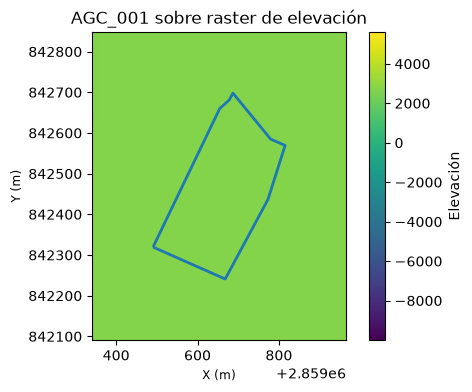

In [54]:
from rasterio.plot import plotting_extent

with rasterio.open(elev_path) as src:
    elevacion = src.read(1)
    extent = plotting_extent(elevacion, src.transform)

fig, ax = plt.subplots(figsize=(6, 4))

# Raster de elevación
im = ax.imshow(
    elevacion,
    extent=extent,
    origin="upper"
)

# Parcela
parcela_repro.boundary.plot(
    ax=ax,
    linewidth=2
)

# Límites de la parcela
xmin, ymin, xmax, ymax = parcela_repro.total_bounds

ax.set_xlim(xmin - 150, xmax + 150)
ax.set_ylim(ymin - 150, ymax + 150)

ax.set_title("AGC_001 sobre raster de elevación")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")

plt.colorbar(im, ax=ax, label="Elevación")
plt.show()

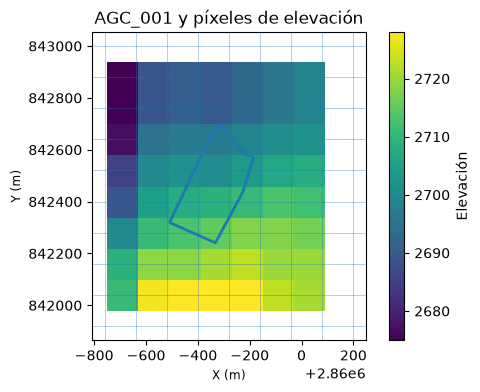

In [55]:
from rasterio.windows import from_bounds

with rasterio.open(elev_path) as src:

    # Límites de AGC_001
    xmin, ymin, xmax, ymax = parcela_repro.total_bounds

    # Agregamos un margen de 2 píxeles
    margen = 240

    window = from_bounds(
        xmin - margen,
        ymin - margen,
        xmax + margen,
        ymax + margen,
        src.transform
    )

    # Leer únicamente esa ventana
    elevacion = src.read(1, window=window)

    # Transformación espacial de la ventana
    transform_window = src.window_transform(window)

    # Convertir NoData a NaN
    elevacion = elevacion.astype(float)
    elevacion[elevacion == src.nodata] = np.nan

    # Extensión espacial
    extent = plotting_extent(
        elevacion,
        transform_window
    )

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(
    elevacion,
    extent=extent,
    origin="upper"
)

# Dibujar la parcela
parcela_repro.boundary.plot(
    ax=ax,
    linewidth=2
)

# Dibujar cuadrícula cada 120 m
x_inicio = extent[0]
x_fin = extent[1]

y_inicio = extent[2]
y_fin = extent[3]

for x in np.arange(
    np.floor(x_inicio / 120) * 120,
    x_fin + 120,
    120
):
    ax.axvline(
        x,
        linewidth=0.5,
        alpha=0.5
    )

for y in np.arange(
    np.floor(y_inicio / 120) * 120,
    y_fin + 120,
    120
):
    ax.axhline(
        y,
        linewidth=0.5,
        alpha=0.5
    )

ax.set_title("AGC_001 y píxeles de elevación")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")

plt.colorbar(
    im,
    ax=ax,
    label="Elevación"
)

plt.show()

En base a la topografía que tenemos de elevación, vamos a sacar la elevación que hay en cada parcela, sacaremos los pixeels que corresponden a cada parcela.

In [56]:
from rasterio.mask import mask

#Considereamos solo ls pixeles en los que la parcela utiliza mas de la mitad del pixel (all_touched=False)
with rasterio.open(elev_path) as src:
    #Extraemos los pixeles que correponsen a la parcela
    elev_parcela, transform = mask(src, parcela_repro.geometry, crop=True, filled=False, all_touched=False)
    
print(elev_parcela.shape)

(1, 5, 3)


Obtuvimos la elevación recortado en base a la parcela, es una banda con 5 filas y tres columnas.

In [57]:
# Quitamos la dimensión correspondiente a la banda
elev_valores = elev_parcela[0]

print("Número total de celdas:", elev_valores.size)
print("Número de celdas válidas:", elev_valores.count())
print("Valores de elevación:")
print(elev_valores.compressed())

Número total de celdas: 15
Número de celdas válidas: 6
Valores de elevación:
[2701. 2704. 2709. 2711. 2713. 2715.]


In [58]:
from rasterio.mask import mask

#Considereamos solo ls pixeles que tocan la parcela (all_touched=True)
with rasterio.open(elev_path) as src:
    #Extraemos los pixeles que correponsen a la parcela
    elev_parce, transform_parcela = mask(src, parcela_repro.geometry, crop=True, filled=False, all_touched=True)
    
print(elev_parce.shape)

(1, 5, 3)


In [59]:

elev_vals = elev_parce[0]

print("Número total de celdas:", elev_vals.size)
print("Número de celdas válidas:", elev_vals.count())
print("Valores de elevación:")
print(elev_vals.compressed())

Número total de celdas: 15
Número de celdas válidas: 13
Valores de elevación:
[2697. 2699. 2702. 2701. 2704. 2708. 2709. 2711. 2713. 2715. 2718. 2719.
 2721.]


Vamos a obtener un área ponderada por pixel, es decir, vamos a ver cuanto peso tiene cada pixel en la parcela, si todo el pixel esta dentro del pixel, tendrá un valor del 100%, su peso será de acuerdo a cuanta parte este dentro de la parcela. Utilizamos la mascara en el que están todos los pixeles que están en la parcela.

Utilizamos `box` de `shapely.geometry` para crear un bounding box.
Y para convertir de pixeeles a coordenadas geográficas utilizamos `xy` de `rasterio.transform`.

In [60]:
from shapely.geometry import box
from rasterio.transform import xy

In [61]:
#Guardamos la geoemetria de la parcela

parcela_geom = parcela_repro.geometry.iloc[0]

In [62]:
pixeles = []

for i in range(elev_vals.shape[0]):
    for j in range(elev_vals.shape[1]):
        
        #Si el pixel esta enmascarado lo ignoramos
        if elev_vals.mask[i, j]:
            continue
        
        #Esquina izquierda superior
        x_iz, y_up = xy(transform_parcela, i, j, offset='ul')
        
        #Esquina inferior derecha
        x_der, y_down = xy(transform_parcela, i, j, offset='lr')
        
        #Bounding box del pixle
        pixel = box(x_iz, y_down, x_der, y_up)        
        
        intersection = pixel.intersection(parcela_geom)
        
        area_intersection = intersection.area
        area_pixel = pixel.area
        proporcion = area_intersection / area_pixel
        
        pixeles.append({
            "fila": i,
            "columna": j,
            "elevacion": elev_vals[i, j],
            "area_pixel_m2": area_pixel,
            "area_interseccion_m2": area_intersection,
            "proporcion": proporcion
        })

In [63]:
df_pixeles = pd.DataFrame(pixeles)

df_pixeles.head()

,fila,columna,elevacion,area_pixel_m2,area_interseccion_m2,proporcion
0,0,1,2697.0,14400.0,2511.258297,0.174393
1,0,2,2699.0,14400.0,128.715312,0.008939
2,1,0,2702.0,14400.0,172.400625,0.011972
3,1,1,2701.0,14400.0,12309.640839,0.854836
4,1,2,2704.0,14400.0,7565.188185,0.525360


In [64]:
print(
    "Área de la parcela:",
    parcela_geom.area,
    "m²"
)

print(
    "Área de intersecciones:",
    df_pixeles["area_interseccion_m2"].sum(),
    "m²"
)


Área de la parcela: 75685.78283383907 m²
Área de intersecciones: 75685.78283386417 m²


In [65]:
elevacion_ponderada = ((df_pixeles['elevacion'] * df_pixeles['area_interseccion_m2']).sum() / df_pixeles['area_interseccion_m2'].sum())

print("Media all_touched=False:", 2708.83)
print("Media all_touched=True:", elev_vals.mean())
print("Media ponderada:", elevacion_ponderada)

Media all_touched=False: 2708.83
Media all_touched=True: 2709.0
Media ponderada: 2708.937487049892


Realizamos una función para replicar con todas las parcelas

In [75]:
from shapely.geometry import mapping

In [76]:
def get_area_coverage(parcela, raster_path):
    with rasterio.open(raster_path) as src:
        parcel_raster = parcela.to_crs(src.crs) #Reproyectamos la parcela para que este igual que el raster
        
        geom = [mapping(parcel_raster.geometry.iloc[0])] # Con mapping pasamos a que sea un diccionario GeoJson
        
        #Recortamos el raster en base a la parcel
        values, transform = mask(src, geom, crop=True, filled=False, all_touched=True)
        
        area_total = parcel_raster.geometry.iloc[0].area
        
        area_valida = 0
        
        for i in range(values.shape[1]):
            for j in range(values.shape[2]):
                
                if values.mask[0, i, j]:
                    continue #Ignoramos los NoData
                
                #Obtenemos coordenadas del pixel
                x_left, y_up = xy(transform, i, j, offset='ul')
                x_right, y_down = xy(transform, i, j, offset='lr')
                
                pixel = box(x_left, y_down, x_right, y_up)
                
                intersection = pixel.intersection(parcel_raster.geometry.iloc[0])
                
                area_valida += intersection.area
        
        coverage = area_valida / area_total
        
        return area_total, area_valida, coverage 
        

In [93]:
#Obtenemos para las 197 parcelas

results_cover = []

for _, parcela in parcelas_gdf.iterrows():
    parcela_gdf = gpd.GeoDataFrame([parcela], crs=parcelas_gdf.crs)
    
    area_total, area_valida, cobertura = get_area_coverage(parcela_gdf, elev_path)
    
    results_cover.append({
        'ID_POLIGON': parcela['ID_POLIGON'],
        'area_total_m2': area_total,
        'area_valida_m2': area_valida,
        'cobertura_valida': cobertura,
        'cobertura_valida_pct': cobertura * 100
    })
    
df_cover = pd.DataFrame(results_cover)
    
    

In [94]:
df_cover.head()

,ID_POLIGON,area_total_m2,area_valida_m2,cobertura_valida,cobertura_valida_pct
0,AGC_196,85130.668788,85130.668788,1.000000,100.000000
1,AGC_044,6760.402971,6760.402971,1.000000,100.000000
2,AGC_020,82856.226598,81059.998963,0.978321,97.832115
3,AGC_174,68423.862739,68423.862739,1.000000,100.000000
4,AGC_083,28466.739798,28466.739798,1.000000,100.000000


In [95]:
df_cover.describe()

,area_total_m2,area_valida_m2,cobertura_valida,cobertura_valida_pct
count,197.000000,197.000000,197.000000,197.000000
mean,65597.429526,65444.193570,0.998210,99.820969
std,73875.350018,73844.041198,0.017765,1.776505
min,3492.578960,3492.578960,0.759380,75.938015
25%,22817.430551,22817.430551,1.000000,100.000000
50%,54211.615219,54211.615219,1.000000,100.000000
75%,80305.789972,79867.439975,1.000000,100.000000
max,638659.004590,638659.004590,1.000000,100.000000


In [96]:
print(
    df_cover[
        df_cover["cobertura_valida_pct"] < 99.999
    ][
        ["ID_POLIGON", "cobertura_valida_pct"]
    ]
)


    ID_POLIGON  cobertura_valida_pct
2      AGC_020             97.832115
163    AGC_023             95.899497
175    AGC_170             75.938015
178    AGC_164             95.061206


In [97]:
parcela_170 = parcelas_gdf[
    parcelas_gdf["ID_POLIGON"] == "AGC_170"
].copy()

parcela_170_6372 = parcela_170.to_crs("EPSG:6372")

In [99]:
print(
    "Área parcela:",
    parcela_170_6372.geometry.iloc[0].area,
    "m²"
)

print(
    "Área válida:",
    df_cover.loc[
        df_cover["ID_POLIGON"] == "AGC_170",
        "area_valida_m2"
    ].iloc[0],
    "m²"
)

Área parcela: 80780.08132865428 m²
Área válida: 61342.79030361965 m²


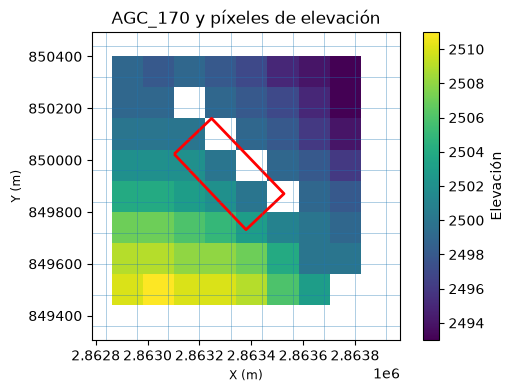

In [101]:
from rasterio.windows import from_bounds

with rasterio.open(elev_path) as src:

    # Límites de AGC_170
    xmin, ymin, xmax, ymax = parcela_170_6372.total_bounds

    # Agregamos un margen de 2 píxeles
    margen = 240

    window = from_bounds(
        xmin - margen,
        ymin - margen,
        xmax + margen,
        ymax + margen,
        src.transform
    )

    # Leer únicamente esa ventana
    elevacion = src.read(1, window=window)

    # Transformación espacial de la ventana
    transform_window = src.window_transform(window)

    # Convertir NoData a NaN
    elevacion = elevacion.astype(float)
    elevacion[elevacion == src.nodata] = np.nan

    # Extensión espacial
    extent = plotting_extent(
        elevacion,
        transform_window
    )

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(
    elevacion,
    extent=extent,
    origin="upper"
)

# Dibujar la parcela
parcela_170_6372.boundary.plot(
    ax=ax,
    linewidth=2,
    color='red'
)

# Dibujar cuadrícula cada 120 m
x_inicio = extent[0]
x_fin = extent[1]

y_inicio = extent[2]
y_fin = extent[3]

for x in np.arange(
    np.floor(x_inicio / 120) * 120,
    x_fin + 120,
    120
):
    ax.axvline(
        x,
        linewidth=0.5,
        alpha=0.5
    )

for y in np.arange(
    np.floor(y_inicio / 120) * 120,
    y_fin + 120,
    120
):
    ax.axhline(
        y,
        linewidth=0.5,
        alpha=0.5
    )

ax.set_title("AGC_170 y píxeles de elevación")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")

plt.colorbar(
    im,
    ax=ax,
    label="Elevación"
)

plt.show()

In [106]:
#Función para obtner un dataframe que relacione la parcela con la elevación

def get_elevation(parcela, elev_path):
    with rasterio.open(elev_path) as src:
        
        parcela_raster = parcela.to_crs(src.crs) #Pasamos la parcela a mismo formato del raster
        
        #Obtenemos el poligono de la parcela
        geom_parcela = parcela_raster.geometry.iloc[0]
        geom = [mapping(geom_parcela)]
        
        #Recortamos la parcela alrededor del raster
        parcela_values, transform = mask(src, geom, crop=True, filled=False, all_touched=True)
        
        #Obtenemos el area de la parcela y obtenemos el area que tiene cada pixel dentro de la parcel
        area_total = geom_parcela.area
        area_valida = 0
        average_sum = 0
        
        for i in range(parcela_values.shape[1]):
            for j in range(parcela_values.shape[2]):
                
                if parcela_values.mask[0, i, j]:
                    continue #Ignoramos los No Data
                    
                #Obtemos el valor del raster
                elevacion = parcela_values[0, i, j]
                
                #Valores del pixel
                x_left, y_up = xy(transform, i, j, offset="ul")
                x_right, y_down = xy(transform, i, j, offset="lr")
                
                # Geometría del píxel
                pixel = box(x_left, y_down, x_right, y_up)
                
                #Obtenemos la parte del pixel que pertenece a la parcela
                intersection = pixel.intersection(geom_parcela)
                area_intersection = intersection.area
                area_valida += area_intersection
                
                average_sum += (float(elevacion) * area_intersection)
        
        # Media ponderada
        if area_valida > 0:
            elevacion_media = average_sum / area_valida
        else:
            elevacion_media = np.nan
        
        # Cobertura válida
        cobertura = area_valida / area_total
        
        return {
            "area_total_m2": area_total,
            "area_valida_m2": area_valida,
            "cobertura_elevacion": cobertura,
            "cobertura_elevacion_pct": cobertura * 100,
            "elevacion_media": elevacion_media
        } 

In [109]:
#Para las 197 parcelas

resultados_elevacion = []

for _, parcela in parcelas_gdf.iterrows():

    resultado = get_elevation(
        gpd.GeoDataFrame(
            [parcela],
            crs=parcelas_gdf.crs
        ),
        elev_path
    )
    
    resultado["ID_POLIGON"] = parcela["ID_POLIGON"]
    
    resultados_elevacion.append(resultado)

In [110]:
df_elevacion = pd.DataFrame(resultados_elevacion)

df_elevacion = df_elevacion[
    [
        "ID_POLIGON",
        "area_total_m2",
        "area_valida_m2",
        "cobertura_elevacion",
        "cobertura_elevacion_pct",
        "elevacion_media"
    ]
]

df_elevacion.head()

,ID_POLIGON,area_total_m2,area_valida_m2,cobertura_elevacion,cobertura_elevacion_pct,elevacion_media
0,AGC_196,85130.668788,85130.668788,1.000000,100.000000,2543.659752
1,AGC_044,6760.402971,6760.402971,1.000000,100.000000,2529.993625
2,AGC_020,82856.226598,81059.998963,0.978321,97.832115,2528.924828
3,AGC_174,68423.862739,68423.862739,1.000000,100.000000,2546.616547
4,AGC_083,28466.739798,28466.739798,1.000000,100.000000,2564.037732


In [111]:
df_elevacion["elevacion_media"].describe()

count     197.000000
mean     2667.102482
std        92.283855
min      2496.648468
25%      2611.351962
50%      2638.902931
75%      2726.683106
max      2906.039520
Name: elevacion_media, dtype: float64

In [112]:
print("Número de parcelas:", len(df_elevacion))
print("Elevaciones NaN:", df_elevacion["elevacion_media"].isna().sum())
print("Coberturas NaN:", df_elevacion["cobertura_elevacion_pct"].isna().sum())

Número de parcelas: 197
Elevaciones NaN: 0
Coberturas NaN: 0


In [113]:
print(
    df_elevacion[
        df_elevacion["cobertura_elevacion_pct"] < 99.999
    ][
        ["ID_POLIGON", "cobertura_elevacion_pct", "elevacion_media"]
    ]
)


    ID_POLIGON  cobertura_elevacion_pct  elevacion_media
2      AGC_020                97.832115      2528.924828
163    AGC_023                95.899497      2502.457298
175    AGC_170                75.938015      2501.227723
178    AGC_164                95.061206      2496.648468


#### Raster pendiente

Ahora vamos a obtener los valores del raster de pendiente en base a la parcela.

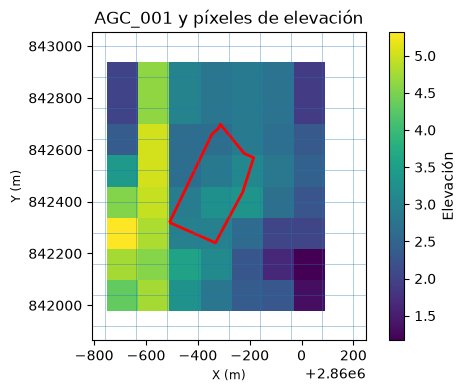

In [ ]:

with rasterio.open(pend_path) as src:

    # Límites de AGC_001
    xmin, ymin, xmax, ymax = parcela_repro.total_bounds

    # Agregamos un margen de 2 píxeles
    margen = 240

    window = from_bounds(
        xmin - margen,
        ymin - margen,
        xmax + margen,
        ymax + margen,
        src.transform
    )

    # Leer únicamente esa ventana
    pendiente = src.read(1, window=window)

    # Transformación espacial de la ventana
    transform_window = src.window_transform(window)

    # Convertir NoData a NaN
    pendiente = pendiente.astype(float)
    pendiente[pendiente == src.nodata] = np.nan

    # Extensión espacial
    extent = plotting_extent(
        pendiente,
        transform_window
    )

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(
    pendiente,
    extent=extent,
    origin="upper"
)

# Dibujar la parcela
parcela_repro.boundary.plot(
    ax=ax,
    linewidth=2,
    color='red'
)

# Dibujar cuadrícula cada 120 m
x_inicio = extent[0]
x_fin = extent[1]

y_inicio = extent[2]
y_fin = extent[3]

for x in np.arange(
    np.floor(x_inicio / 120) * 120,
    x_fin + 120,
    120
):
    ax.axvline(
        x,
        linewidth=0.5,
        alpha=0.5
    )

for y in np.arange(
    np.floor(y_inicio / 120) * 120,
    y_fin + 120,
    120
):
    ax.axhline(
        y,
        linewidth=0.5,
        alpha=0.5
    )

ax.set_title("AGC_001 y píxeles de elevación")
ax.set_xlabel("X ")
ax.set_ylabel("Y ")

plt.colorbar(
    im,
    ax=ax,
    label="Pendiente"
)

plt.show()

In [67]:
#Considereamos solo ls pixeles que tocan la parcela (all_touched=True)
with rasterio.open(pend_path) as src:
    #Extraemos los pixeles que correponsen a la parcela
    pend_parcela, transform_pend_parcela = mask(src, parcela_repro.geometry, crop=True, filled=False, all_touched=True)
    
print(pend_parcela.shape)

(1, 5, 3)


In [68]:

pend_vals = pend_parcela[0]

print("Número total de celdas:", pend_vals.size)
print("Número de celdas válidas:", pend_vals.count())
print("Valores de elevación:")
print(pend_vals.compressed())

Número total de celdas: 15
Número de celdas válidas: 13
Valores de elevación:
[2.6671813 2.8821812 2.6671813 2.8537097 3.1004913 2.9079316 3.2534685
 3.3182275 2.9814613 2.9802706 2.6201558 3.5574577 3.1380274]


In [69]:
pixeles_pend = []

for i in range(pend_vals.shape[0]):
    for j in range(pend_vals.shape[1]):
        
        #Si el pixel esta enmascarado lo ignoramos
        if pend_vals.mask[i, j]:
            continue
        
        #Esquina izquierda superior
        x_iz, y_up = xy(transform_pend_parcela, i, j, offset='ul')
        
        #Esquina inferior derecha
        x_der, y_down = xy(transform_pend_parcela, i, j, offset='lr')
        
        #Bounding box del pixle
        pixel = box(x_iz, y_down, x_der, y_up)        
        
        intersection = pixel.intersection(parcela_geom)
        
        area_intersection = intersection.area
        area_pixel = pixel.area
        proporcion = area_intersection / area_pixel
        
        pixeles_pend.append({
            "fila": i,
            "columna": j,
            "pendiente": pend_vals[i, j],
            "area_pixel_m2": area_pixel,
            "area_interseccion_m2": area_intersection,
            "proporcion": proporcion
        })

In [70]:
pixeles_pend_df = pd.DataFrame(pixeles_pend)

pixeles_pend_df.head()

,fila,columna,pendiente,area_pixel_m2,area_interseccion_m2,proporcion
0,0,1,2.667181,14400.0,2511.258297,0.174393
1,0,2,2.882181,14400.0,128.715312,0.008939
2,1,0,2.667181,14400.0,172.400625,0.011972
3,1,1,2.853710,14400.0,12309.640839,0.854836
4,1,2,3.100491,14400.0,7565.188185,0.525360


In [71]:
pendiente_ponderada = ((pixeles_pend_df['pendiente'] * pixeles_pend_df['area_interseccion_m2']).sum() / pixeles_pend_df['area_interseccion_m2'].sum())
print("Media all_touched=True:", pend_vals.mean())
print("Media ponderada:", pendiente_ponderada)

Media all_touched=True: 2.9944416926457333
Media ponderada: 3.039547531881103


In [72]:
print("Área parcela:", parcela_geom.area)
print("Área suma intersecciones:", pixeles_pend_df["area_interseccion_m2"].sum())

Área parcela: 75685.78283383907
Área suma intersecciones: 75685.78283386417


In [73]:
area_total =parcela_geom.area

area_valida = pixeles_pend_df["area_interseccion_m2"].sum()

cobertura_valida = area_valida / area_total

print("Área total de la parcela:", area_total)
print("Área válida:", area_valida)
print("Cobertura válida:", cobertura_valida)
print("Cobertura válida (%):", cobertura_valida * 100)

Área total de la parcela: 75685.78283383907
Área válida: 75685.78283386417
Cobertura válida: 1.0000000000003317
Cobertura válida (%): 100.00000000003317


In [114]:
def get_slope(parcela, raster_path):
    
    with rasterio.open(raster_path) as src:
        
        # Reproyectar parcela al CRS del raster
        parcela_raster = parcela.to_crs(src.crs)
        
        # Geometría de la parcela
        geom_parcela = parcela_raster.geometry.iloc[0]
        geom = [mapping(geom_parcela)]
        
        # Recortar raster alrededor de la parcela
        valores, transform = mask(
            src,
            geom,
            crop=True,
            filled=False,
            all_touched=True
        )
        
        # Área total
        area_total = geom_parcela.area
        
        area_valida = 0
        suma_ponderada = 0
        
        # Recorrer píxeles
        for fila in range(valores.shape[1]):
            for columna in range(valores.shape[2]):
                
                # Ignorar NoData
                if valores.mask[0, fila, columna]:
                    continue
                
                # Valor de pendiente
                pendiente = valores[0, fila, columna]
                
                # Coordenadas del píxel
                x_izq, y_sup = rasterio.transform.xy(
                    transform,
                    fila,
                    columna,
                    offset="ul"
                )
                
                x_der, y_inf = rasterio.transform.xy(
                    transform,
                    fila,
                    columna,
                    offset="lr"
                )
                
                # Geometría del píxel
                pixel = box(
                    x_izq,
                    y_inf,
                    x_der,
                    y_sup
                )
                
                # Intersección con la parcela
                interseccion = pixel.intersection(geom_parcela)
                
                area_interseccion = interseccion.area
                
                # Área válida
                area_valida += area_interseccion
                
                # Pendiente × área
                suma_ponderada += (
                    float(pendiente) *
                    area_interseccion
                )
        
        # Media ponderada
        if area_valida > 0:
            pendiente_media = suma_ponderada / area_valida
        else:
            pendiente_media = np.nan
        
        # Cobertura
        cobertura = area_valida / area_total
        
        return {
            "area_total_m2": area_total,
            "area_valida_m2": area_valida,
            "cobertura_pendiente": cobertura,
            "cobertura_pendiente_pct": cobertura * 100,
            "pendiente_media": pendiente_media
        }

In [115]:
parcela_001 = parcelas_gdf[
    parcelas_gdf["ID_POLIGON"] == "AGC_001"
].copy()

resultado_001_pendiente = get_slope(
    parcela_001,
    pend_path
)

print(resultado_001_pendiente)

{'area_total_m2': 75685.78283383907, 'area_valida_m2': 75685.78283386417, 'cobertura_pendiente': 1.0000000000003317, 'cobertura_pendiente_pct': 100.00000000003317, 'pendiente_media': 3.039547531881103}


In [117]:
resultados_pendiente = []

for _, parcela in parcelas_gdf.iterrows():

    resultado = get_slope(gpd.GeoDataFrame([parcela], crs=parcelas_gdf.crs),pend_path)
    
    resultado["ID_POLIGON"] = parcela["ID_POLIGON"]
    
    resultados_pendiente.append(resultado)

In [119]:
df_pendiente = pd.DataFrame(resultados_pendiente)

df_pendiente = df_pendiente[
    [
        "ID_POLIGON",
        "area_total_m2",
        "area_valida_m2",
        "cobertura_pendiente",
        "cobertura_pendiente_pct",
        "pendiente_media"
    ]
]

In [120]:
print(df_pendiente.head())

  ID_POLIGON  area_total_m2  area_valida_m2  cobertura_pendiente  \
0    AGC_196   85130.668788    85130.668788             1.000000   
1    AGC_044    6760.402971     6626.924578             0.980256   
2    AGC_020   82856.226598    54063.973641             0.652503   
3    AGC_174   68423.862739    68423.862739             1.000000   
4    AGC_083   28466.739798    28466.739798             1.000000   

   cobertura_pendiente_pct  pendiente_media  
0               100.000000         1.740829  
1                98.025585         0.348862  
2                65.250345         0.561396  
3               100.000000         2.284557  
4               100.000000         2.368227  


In [121]:
display(df_pendiente.describe())

,area_total_m2,area_valida_m2,cobertura_pendiente,cobertura_pendiente_pct,pendiente_media
count,197.000000,197.000000,197.000000,197.000000,197.000000
mean,65597.429526,64504.267353,0.987273,98.727300,2.792785
std,73875.350018,73963.106477,0.094683,9.468278,2.050182
min,3492.578960,1693.874926,0.020969,2.096897,0.281865
25%,22817.430551,22374.682623,1.000000,100.000000,1.149426
50%,54211.615219,49747.111690,1.000000,100.000000,2.126439
75%,80305.789972,79510.179166,1.000000,100.000000,3.891151
max,638659.004590,638659.004590,1.000000,100.000000,9.396395


In [122]:
print(
    df_pendiente[
        df_pendiente["cobertura_pendiente_pct"] < 99.999
    ][
        [
            "ID_POLIGON",
            "cobertura_pendiente_pct",
            "pendiente_media"
        ]
    ]
)

    ID_POLIGON  cobertura_pendiente_pct  pendiente_media
1      AGC_044                98.025585         0.348862
2      AGC_020                65.250345         0.561396
163    AGC_023                28.635263         1.766181
175    AGC_170                 2.096897         1.391080
178    AGC_164                55.269931         0.903925


Tenemos un problema con la parcela AGC_170 porque solo cubre 2% y con AGC_023 porque solo subr 28%. 

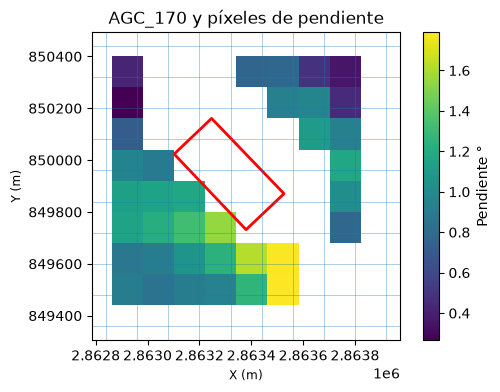

In [134]:
parcela_170 = parcelas_gdf[parcelas_gdf['ID_POLIGON'] == 'AGC_170'].copy()

with rasterio.open(pend_path) as src:
    
    # Reproyectar la parcela al CRS del raster
    parcela_170 = parcela_170.to_crs(src.crs)


    # Límites de AGC_170
    xmin, ymin, xmax, ymax = parcela_170.total_bounds

    # Agregamos un margen de 2 píxeles
    margen = 240

    window = from_bounds(
        xmin - margen,
        ymin - margen,
        xmax + margen,
        ymax + margen,
        src.transform
    )

    # Leer únicamente esa ventana
    pendiente = src.read(1, window=window)

    # Transformación espacial de la ventana
    transform_window = src.window_transform(window)

    # Convertir NoData a NaN
    pendiente = pendiente.astype(float)
    pendiente[pendiente == src.nodata] = np.nan

    # Extensión espacial
    extent = plotting_extent(
        pendiente,
        transform_window
    )

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(
    pendiente,
    extent=extent,
    origin="upper"
)

# Dibujar la parcela
parcela_170.boundary.plot(
    ax=ax,
    linewidth=2,
    color='red'
)

# Dibujar cuadrícula cada 120 m
x_inicio = extent[0]
x_fin = extent[1]

y_inicio = extent[2]
y_fin = extent[3]

for x in np.arange(
    np.floor(x_inicio / 120) * 120,
    x_fin + 120,
    120
):
    ax.axvline(
        x,
        linewidth=0.5,
        alpha=0.5
    )

for y in np.arange(
    np.floor(y_inicio / 120) * 120,
    y_fin + 120,
    120
):
    ax.axhline(
        y,
        linewidth=0.5,
        alpha=0.5
    )

ax.set_title("AGC_170 y píxeles de pendiente")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")

plt.colorbar(
    im,
    ax=ax,
    label="Pendiente °" 
)

plt.show()

#### Unimos df de Elevación y Pendiente

In [140]:
df_topografia = df_elevacion.merge(df_pendiente, on='ID_POLIGON', how='inner', suffixes=('_elevacion', '_pendiente'))

df_topografia = df_topografia[
    [
        "ID_POLIGON",
        "elevacion_media",
        "cobertura_elevacion_pct",
        "pendiente_media",
        "cobertura_pendiente_pct"
    ]
]

In [141]:
df_topografia.head()

,ID_POLIGON,elevacion_media,cobertura_elevacion_pct,pendiente_media,cobertura_pendiente_pct
0,AGC_196,2543.659752,100.000000,1.740829,100.000000
1,AGC_044,2529.993625,100.000000,0.348862,98.025585
2,AGC_020,2528.924828,97.832115,0.561396,65.250345
3,AGC_174,2546.616547,100.000000,2.284557,100.000000
4,AGC_083,2564.037732,100.000000,2.368227,100.000000


In [143]:
df_topografia['ID_POLIGON'].nunique()

197